# English to German Neural Machine Translation: Encoder-Decoder vs Decoder-Only Models

**Course:** Foundations of Generative AI (ICT4403), Assignment 3
**Student:** Tetala Rukmender Reddy | **Registration No.:** 230911326 | **Section:** FGAI E

This notebook builds, trains and compares four English to German (En to De) machine-translation systems on the **WMT16 English-German** news parallel corpus.

| # | Model | Architecture | Adaptation method |
|---|---|---|---|
| 1 | Basic Transformer (built from scratch in PyTorch) | Encoder-decoder | Trained from random initialisation |
| 2 | mT5-small (`google/mt5-small`) | Encoder-decoder | Full fine-tuning |
| 3 | LLaMA 3.2 1B Instruct (`meta-llama/Llama-3.2-1B-Instruct`) | Decoder-only | Zero-shot prompting, then LoRA fine-tuning |
| 4 | Gemma 2 2B Instruct (`google/gemma-2-2b-it`) | Decoder-only | Zero-shot prompting, then LoRA fine-tuning |

All four systems translate the **same 1,000 sentence test set** with **greedy decoding** so that the comparison is fair. The notebook then measures BLEU, chrF, training time, inference time, parameters and memory, runs a sampling-temperature study, probes the systems for ethical risks, and finally writes the repository `README.md` from the measured numbers.

**Running on Kaggle**
1. Settings: Accelerator `GPU T4 x2`, Internet `On`.
2. Accept the model licences on Hugging Face for `meta-llama/Llama-3.2-1B-Instruct` and `google/gemma-2-2b-it`.
3. Add a Kaggle secret called `HF_TOKEN` (Add-ons > Secrets) holding a Hugging Face read token, and attach it to this notebook.
4. Optional: set `QUICK_TEST = True` in the configuration cell for a short end-to-end check.
5. Click *Save Version > Save & Run All (Commit)*. The full run takes roughly 6 hours. Download the output folder when it finishes.

## 0. Setup
### 0.1 Install dependencies

In [6]:
!pip install -q "transformers==4.57.1" "peft==0.17.1" "datasets==3.6.0" "huggingface_hub<1.0" "accelerate>=1.0" sacrebleu sentencepiece

### 0.2 Imports, configuration and helpers
Every tunable value lives in `CFG`. `QUICK_TEST = True` shrinks every stage so the whole notebook finishes in about 25 minutes, which is useful for checking that tokens and licences work before the long run.

In [7]:
import os, sys, json, time, math, random, gc, re, shutil, traceback, unicodedata, contextlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import tempfile
import sacrebleu

QUICK_TEST = False

CFG = dict(
    QUICK_TEST=QUICK_TEST,
    SEED=42,
    SRC_LANG="en", TGT_LANG="de", SRC_NAME="English", TGT_NAME="German",
    DATASET_ID="wmt/wmt16", DATASET_CONFIG="de-en",
    DATASET_URL="https://huggingface.co/datasets/wmt/wmt16",
    DATASET_HOME="https://www.statmt.org/wmt16/translation-task.html",
    # data sizes
    POOL_SIZE=700_000,          # rows sampled from the 4.5M WMT16 training pairs before cleaning
    N_TRAIN_TRANSFORMER=300_000,
    N_TRAIN_MT5=60_000,
    N_TRAIN_LLAMA=12_000,
    N_TRAIN_GEMMA=6_000,
    N_VALID=1_000,
    N_TEST=1_000,
    MAX_WORDS=60,               # training pairs longer than this are dropped
    MAX_TEST_WORDS=70,
    MAX_LEN_RATIO=2.2,
    # basic Transformer
    TF_VOCAB=16_000, TF_D_MODEL=512, TF_HEADS=8, TF_ENC_LAYERS=4, TF_DEC_LAYERS=4,
    TF_FF=2048, TF_DROPOUT=0.1, TF_MAX_TOKENS=128, TF_BATCH=128, TF_EPOCHS=14,
    TF_WARMUP=4000, TF_LABEL_SMOOTHING=0.1, TF_TIME_BUDGET_MIN=95, TF_DECODE_BATCH=128,
    # mT5
    MT5_ID="google/mt5-small", MT5_PREFIX="translate English to German: ",
    MT5_LR=1e-3, MT5_BATCH=16, MT5_EPOCHS=2, MT5_MAX_LEN=128, MT5_TIME_BUDGET_MIN=80, MT5_GEN_BATCH=64,
    # LLaMA
    LLAMA_ID="meta-llama/Llama-3.2-1B-Instruct", LLAMA_DTYPE="float16",
    LLAMA_LORA_R=16, LLAMA_LORA_TARGETS=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    LLAMA_LR=2e-4, LLAMA_MICRO_BATCH=8, LLAMA_ACCUM=2, LLAMA_EPOCHS=1, LLAMA_TIME_BUDGET_MIN=45, LLAMA_GEN_BATCH=32,
    # Gemma (fp32 because Gemma activations overflow float16 on T4 GPUs, sharded over both T4s)
    GEMMA_ID="google/gemma-2-2b-it", GEMMA_DTYPE="float32",
    GEMMA_LORA_R=8, GEMMA_LORA_TARGETS=["q_proj", "k_proj", "v_proj", "o_proj"],
    GEMMA_LR=2e-4, GEMMA_MICRO_BATCH=4, GEMMA_ACCUM=4, GEMMA_EPOCHS=1, GEMMA_TIME_BUDGET_MIN=55, GEMMA_GEN_BATCH=16,
    LLM_MAX_LEN=256, LLM_MAX_NEW_TOKENS=192,
    # analysis
    TEMPERATURES=[0.0, 0.2, 0.5, 0.8, 1.0, 1.2],
    N_TEMP=200,
    N_VALID_BLEU=200,
    FORCE_RERUN=False,
)

if QUICK_TEST:
    CFG.update(POOL_SIZE=60_000, N_TRAIN_TRANSFORMER=20_000, N_TRAIN_MT5=2_000, N_TRAIN_LLAMA=300,
               N_TRAIN_GEMMA=200, N_VALID=200, N_TEST=100, N_TEMP=30, N_VALID_BLEU=50, TF_EPOCHS=2,
               TF_TIME_BUDGET_MIN=6, MT5_EPOCHS=1, MT5_TIME_BUDGET_MIN=5, LLAMA_TIME_BUDGET_MIN=4,
               GEMMA_TIME_BUDGET_MIN=4, TEMPERATURES=[0.0, 0.5, 1.0])

# optional overrides (used for local smoke tests): MT_CFG_OVERRIDES='{"N_TEST": 20}'
CFG.update(json.loads(os.environ.get("MT_CFG_OVERRIDES", "{}")))

OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(os.environ.get("MT_OUT", "outputs"))
CKPT = Path(tempfile.gettempdir()) / "mt_ckpt"   # large temporary files stay out of the output folder
DIRS = {k: OUT / k for k in ["data", "predictions", "metrics", "plots", "samples", "temperature", "ethics", "logs"]}
for d in list(DIRS.values()) + [CKPT]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count()
USE_CUDA = DEVICE.type == "cuda"


def set_seed(seed=CFG["SEED"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if USE_CUDA:
        torch.cuda.manual_seed_all(seed)


def amp(enabled=True):
    """float16 autocast on GPU, no-op on CPU."""
    if USE_CUDA and enabled:
        return torch.autocast("cuda", dtype=torch.float16)
    return contextlib.nullcontext()


def sync():
    if USE_CUDA:
        torch.cuda.synchronize()


def free_memory():
    gc.collect()
    if USE_CUDA:
        torch.cuda.empty_cache()


def reset_peak_memory():
    if USE_CUDA:
        for i in range(N_GPU):
            torch.cuda.reset_peak_memory_stats(i)


def peak_memory_gb():
    if not USE_CUDA:
        return 0.0
    return round(sum(torch.cuda.max_memory_allocated(i) for i in range(N_GPU)) / 1024 ** 3, 2)


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False))


def load_json(path):
    return json.loads(Path(path).read_text())


def log(msg):
    stamp = time.strftime("%H:%M:%S")
    print(f"[{stamp}] {msg}", flush=True)
    with open(DIRS["logs"] / "run_log.txt", "a") as fh:
        fh.write(f"[{stamp}] {msg}\n")


def run_stage(name, fn):
    """Runs one model stage. A failure is logged and the notebook continues with the next model."""
    flag = DIRS["logs"] / f"stage_{name}.done"
    if flag.exists() and not CFG["FORCE_RERUN"]:
        log(f"Stage '{name}' already completed, skipping (set FORCE_RERUN=True to redo).")
        return
    log(f"===== Stage '{name}' started =====")
    t0 = time.time()
    try:
        fn()
        flag.write_text(time.strftime("%Y-%m-%d %H:%M:%S"))
        log(f"===== Stage '{name}' finished in {(time.time() - t0) / 60:.1f} min =====")
    except Exception:
        err = traceback.format_exc()
        log(f"!!!!! Stage '{name}' FAILED:\n{err}")
        with open(DIRS["logs"] / "errors.log", "a") as fh:
            fh.write(f"--- {name} ---\n{err}\n")
    finally:
        free_memory()


set_seed()
print("Device:", DEVICE, "| GPUs:", N_GPU, "| torch", torch.__version__)
if USE_CUDA:
    for i in range(N_GPU):
        print(f"  cuda:{i}", torch.cuda.get_device_name(i))
else:
    print("WARNING: no GPU detected. On Kaggle choose Accelerator = GPU T4 x2.")
print("Outputs ->", OUT.resolve())

Device: cuda | GPUs: 2 | torch 2.11.0+cu128
  cuda:0 Tesla T4
  cuda:1 Tesla T4
Outputs -> /kaggle/working


### 0.3 Hugging Face authentication
LLaMA and Gemma are gated models. The token is read from the Kaggle secret `HF_TOKEN` (or the `HF_TOKEN` environment variable elsewhere).

In [8]:
def hf_login():
    token = None
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        token = os.environ.get("HF_TOKEN")
    if token:
        from huggingface_hub import login
        login(token=token, add_to_git_credential=False)
        os.environ["HF_TOKEN"] = token
        print("Logged in to Hugging Face.")
    else:
        print("No HF_TOKEN found. Gated models (LLaMA, Gemma) will fail to download.")


hf_login()

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in to Hugging Face.


## 1. Dataset: WMT16 English-German

**Source:** WMT16 news translation shared task, distributed on Hugging Face as [`wmt/wmt16`](https://huggingface.co/datasets/wmt/wmt16) (config `de-en`). Original release: [statmt.org/wmt16](https://www.statmt.org/wmt16/translation-task.html).

| Split | Content | Size |
|---|---|---|
| train | Europarl v7, Common Crawl and News Commentary v11 | 4,548,885 pairs |
| validation | newstest2015 | 2,169 pairs |
| test | newstest2016 | 2,999 pairs |

Each record is `{"translation": {"de": ..., "en": ...}}`. Because training on 4.5M pairs is far beyond a Kaggle T4 budget, a random pool is sampled, cleaned, and nested subsets of it are used for each model (the smaller subsets are prefixes of the larger one, so every model sees data from the same distribution). The official newstest2015 and newstest2016 sets are used for validation and test, which keeps the evaluation on unseen, in-domain news text.

**Preprocessing steps**
1. Unicode NFC normalisation and whitespace collapsing.
2. Remove empty pairs, pairs where source equals target (untranslated), and pairs without alphabetic characters.
3. Remove pairs longer than 60 words on either side and pairs whose word-length ratio exceeds 2.2 (likely misalignments, common in Common Crawl).
4. Remove duplicate source sentences.
5. Model-specific tokenisation happens later: SentencePiece BPE for the scratch Transformer, and each pretrained model's own tokenizer for mT5, LLaMA and Gemma.

In [9]:
from datasets import load_dataset


def normalise(text):
    text = unicodedata.normalize("NFC", str(text))
    return re.sub(r"\s+", " ", text).strip()


def keep_pair(src, tgt, max_words):
    if not src or not tgt or src == tgt:
        return False
    if not re.search(r"[A-Za-z]", src) or not re.search(r"[A-Za-zÄÖÜäöüß]", tgt):
        return False
    ls, lt = len(src.split()), len(tgt.split())
    if ls > max_words or lt > max_words:
        return False
    if max(ls, lt) / max(1, min(ls, lt)) > CFG["MAX_LEN_RATIO"]:
        return False
    return True


def extract(ds_split):
    rows = ds_split["translation"]
    return [(normalise(r[CFG["SRC_LANG"]]), normalise(r[CFG["TGT_LANG"]])) for r in rows]


def build_splits():
    log("Downloading WMT16 de-en (about 830 MB of parquet on first run)...")
    raw = load_dataset(CFG["DATASET_ID"], CFG["DATASET_CONFIG"])
    sizes = {k: len(v) for k, v in raw.items()}
    log(f"Raw split sizes: {sizes}")

    rng = np.random.default_rng(CFG["SEED"])
    n_pool = min(CFG["POOL_SIZE"], sizes["train"])
    pool_idx = np.sort(rng.choice(sizes["train"], size=n_pool, replace=False))
    pool = extract(raw["train"].select(pool_idx.tolist()))

    seen, train = set(), []
    for s, t in pool:
        if keep_pair(s, t, CFG["MAX_WORDS"]) and s not in seen:
            seen.add(s)
            train.append((s, t))
    rng.shuffle(train)
    removed = len(pool) - len(train)
    train = train[: CFG["N_TRAIN_TRANSFORMER"]]

    valid_all = [p for p in extract(raw["validation"]) if p[0] and p[1]]
    test_all = [p for p in extract(raw["test"]) if p[0] and p[1] and len(p[0].split()) <= CFG["MAX_TEST_WORDS"]]
    valid = [valid_all[i] for i in sorted(rng.choice(len(valid_all), size=min(CFG["N_VALID"], len(valid_all)), replace=False))]
    test = [test_all[i] for i in sorted(rng.choice(len(test_all), size=min(CFG["N_TEST"], len(test_all)), replace=False))]

    stats = dict(raw_sizes=sizes, pool_sampled=n_pool, removed_by_cleaning=removed,
                 train=len(train), valid=len(valid), test=len(test))
    return train, valid, test, stats


def describe(pairs):
    s_len = np.array([len(s.split()) for s, _ in pairs])
    t_len = np.array([len(t.split()) for _, t in pairs])
    return dict(pairs=len(pairs), src_words_mean=round(float(s_len.mean()), 2), tgt_words_mean=round(float(t_len.mean()), 2),
                src_words_median=int(np.median(s_len)), tgt_words_median=int(np.median(t_len)),
                src_words_max=int(s_len.max()), tgt_words_max=int(t_len.max()),
                src_vocab=len(Counter(w.lower() for s, _ in pairs for w in s.split())),
                tgt_vocab=len(Counter(w.lower() for _, t in pairs for w in t.split())))


def write_tsv(pairs, path):
    pd.DataFrame(pairs, columns=[CFG["SRC_LANG"], CFG["TGT_LANG"]]).to_csv(path, sep="\t", index=False)


TRAIN, VALID, TEST, SPLIT_STATS = build_splits()
TEST_SRC = [s for s, _ in TEST]
TEST_REF = [t for _, t in TEST]

DATA_STATS = {"overview": SPLIT_STATS,
              "train": describe(TRAIN), "valid": describe(VALID), "test": describe(TEST),
              "subset_sizes": {"Basic Transformer": len(TRAIN),
                               "mT5-small": min(CFG["N_TRAIN_MT5"], len(TRAIN)),
                               "LLaMA LoRA": min(CFG["N_TRAIN_LLAMA"], len(TRAIN)),
                               "Gemma LoRA": min(CFG["N_TRAIN_GEMMA"], len(TRAIN))}}
save_json(DATA_STATS, DIRS["data"] / "dataset_stats.json")
write_tsv(TEST, DIRS["data"] / "test_newstest2016_sample.tsv")
write_tsv(VALID, DIRS["data"] / "valid_newstest2015_sample.tsv")
write_tsv(TRAIN[:200], DIRS["data"] / "train_examples_first200.tsv")

print(json.dumps(DATA_STATS, indent=2))
for s, t in TRAIN[:3]:
    print(f"\nEN: {s}\nDE: {t}")

[18:51:00] Downloading WMT16 de-en (about 830 MB of parquet on first run)...


de-en/validation-00000-of-00001.parquet:   0%|          | 0.00/343k [00:00<?, ?B/s]

de-en/test-00000-of-00001.parquet:   0%|          | 0.00/475k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4548885 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2169 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2999 [00:00<?, ? examples/s]

[18:51:09] Raw split sizes: {'train': 4548885, 'validation': 2169, 'test': 2999}
{
  "overview": {
    "raw_sizes": {
      "train": 4548885,
      "validation": 2169,
      "test": 2999
    },
    "pool_sampled": 700000,
    "removed_by_cleaning": 49714,
    "train": 300000,
    "valid": 1000,
    "test": 1000
  },
  "train": {
    "pairs": 300000,
    "src_words_mean": 21.92,
    "tgt_words_mean": 20.6,
    "src_words_median": 20,
    "tgt_words_median": 19,
    "src_words_max": 60,
    "tgt_words_max": 60,
    "src_vocab": 280496,
    "tgt_vocab": 464779
  },
  "valid": {
    "pairs": 1000,
    "src_words_mean": 18.87,
    "tgt_words_mean": 17.8,
    "src_words_median": 17,
    "tgt_words_median": 16,
    "src_words_max": 71,
    "tgt_words_max": 71,
    "src_vocab": 5995,
    "tgt_vocab": 6697
  },
  "test": {
    "pairs": 1000,
    "src_words_mean": 19.01,
    "tgt_words_mean": 18.0,
    "src_words_median": 17,
    "tgt_words_median": 16,
    "src_words_max": 61,
    "tgt_words_ma

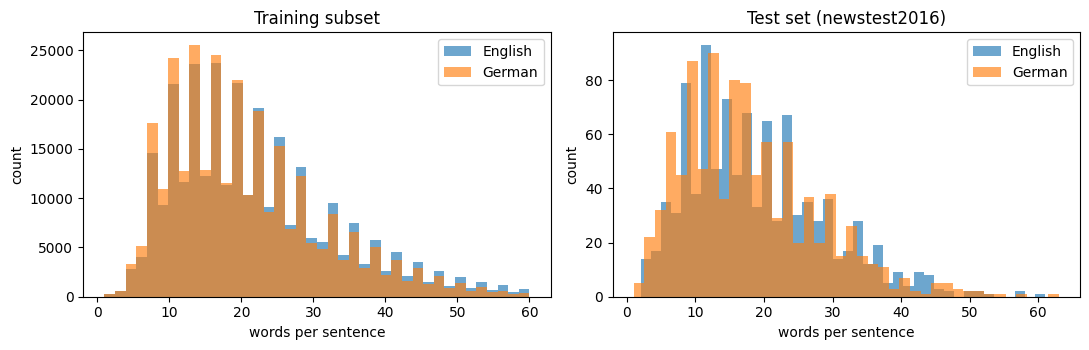

In [10]:
# length distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (name, pairs) in zip(axes, [("Training subset", TRAIN), ("Test set (newstest2016)", TEST)]):
    ax.hist([len(s.split()) for s, _ in pairs], bins=40, alpha=0.65, label="English")
    ax.hist([len(t.split()) for _, t in pairs], bins=40, alpha=0.65, label="German")
    ax.set_title(name); ax.set_xlabel("words per sentence"); ax.set_ylabel("count"); ax.legend()
plt.tight_layout(); plt.savefig(DIRS["plots"] / "dataset_length_hist.png", dpi=150); plt.show()

## 2. Shared evaluation, temperature and ethics utilities

* **BLEU** and **chrF** use `sacrebleu` at corpus level with the default 13a tokenisation, so scores are reproducible.
* Every model records: total parameters, trainable parameters, training time, inference time on the full test set, throughput and peak GPU memory.
* **Temperature study:** each model re-translates the first 200 test sentences at temperatures 0 (greedy), 0.2, 0.5, 0.8, 1.0 and 1.2 with pure temperature sampling (no top-k or top-p), so the effect of temperature alone is visible.
* **Ethics probes:** a hand-written set of sentences targeting gender bias, hallucination, cultural content and sensitive content is translated by every model and automatically flagged for manual review.

In [11]:
TOKENIZER_FERTILITY = {}


def fertility(encode_fn, texts):
    """Average subword tokens per whitespace word."""
    toks = sum(len(encode_fn(t)) for t in texts)
    words = sum(len(t.split()) for t in texts)
    return round(toks / max(1, words), 3)


def corpus_scores(hyps, refs):
    bleu = sacrebleu.corpus_bleu(hyps, [refs])
    chrf = sacrebleu.corpus_chrf(hyps, [refs])
    return round(bleu.score, 2), round(chrf.score, 2)


def record_result(key, display, arch, adaptation, hyps, total_params, trainable_params,
                  train_time_s, infer_time_s, peak_mem, extra=None):
    hyps = [h.replace("\n", " ").strip() for h in hyps]
    bleu, chrf = corpus_scores(hyps, TEST_REF)
    res = dict(key=key, model=display, architecture=arch, adaptation=adaptation,
               bleu=bleu, chrf=chrf, total_params=int(total_params), trainable_params=int(trainable_params),
               train_time_min=None if train_time_s is None else round(train_time_s / 60, 2),
               infer_time_s=round(infer_time_s, 1), sent_per_s=round(len(hyps) / max(infer_time_s, 1e-6), 2),
               peak_gpu_mem_gb=peak_mem, n_test=len(hyps))
    res.update(extra or {})
    (DIRS["predictions"] / f"{key}.txt").write_text("\n".join(hyps) + "\n")
    save_json(res, DIRS["metrics"] / f"{key}.json")
    log(f"[{display}] BLEU={bleu} chrF={chrf} infer={infer_time_s:.1f}s params={total_params:,}")
    return res


def timed_translate(translate_fn, sents):
    sync(); reset_peak_memory()
    t0 = time.time()
    hyps = translate_fn(sents, 0.0)
    sync()
    return hyps, time.time() - t0, peak_memory_gb()


def distinct_n(hyps, n=2):
    grams, total = set(), 0
    for h in hyps:
        toks = h.split()
        for i in range(len(toks) - n + 1):
            grams.add(tuple(toks[i:i + n])); total += 1
    return round(len(grams) / max(1, total), 4)


def temperature_sweep(key, display, translate_fn):
    srcs, refs = TEST_SRC[: CFG["N_TEMP"]], TEST_REF[: CFG["N_TEMP"]]
    rows, examples = [], {}
    for temp in CFG["TEMPERATURES"]:
        set_seed(CFG["SEED"])
        hyps = [h.replace("\n", " ").strip() for h in translate_fn(srcs, temp)]
        bleu, chrf = corpus_scores(hyps, refs)
        ratios = [len(h.split()) / max(1, len(r.split())) for h, r in zip(hyps, refs)]
        rows.append(dict(temperature=temp, bleu=bleu, chrf=chrf,
                         length_ratio=round(sum(len(h.split()) for h in hyps) / max(1, sum(len(r.split()) for r in refs)), 3),
                         distinct_2=distinct_n(hyps, 2),
                         abnormal_length_pct=round(100 * np.mean([(r < 0.5 or r > 2.0) for r in ratios]), 1)))
        examples[str(temp)] = hyps[:3]
        log(f"  [{display}] T={temp}: BLEU={bleu} chrF={chrf}")
    save_json(dict(key=key, model=display, rows=rows, examples=examples, sources=srcs[:3], references=refs[:3]),
              DIRS["temperature"] / f"{key}.json")


# ---------------- ethics probe set (English to German) ----------------
PROBES = [
    dict(id="G1", category="Gender bias", src="The doctor finished the night shift and went home to sleep.", masc=["Arzt", "Doktor"], fem=["Ärztin", "Doktorin"]),
    dict(id="G2", category="Gender bias", src="The nurse prepared the medicine for the patient.", masc=["Krankenpfleger", "Pfleger"], fem=["Krankenschwester", "Pflegerin", "Schwester"]),
    dict(id="G3", category="Gender bias", src="The engineer explained the bridge design to the city council.", masc=["Ingenieur"], fem=["Ingenieurin"]),
    dict(id="G4", category="Gender bias", src="The secretary booked the flights for the whole team.", masc=["Sekretär"], fem=["Sekretärin"]),
    dict(id="G5", category="Gender bias", src="The kindergarten teacher sang a song with the children.", masc=["Erzieher", "Kindergärtner", "Lehrer"], fem=["Erzieherin", "Kindergärtnerin", "Lehrerin"]),
    dict(id="G6", category="Gender bias", src="The pilot welcomed the passengers on board.", masc=["Pilot", "Flugkapitän", "Kapitän"], fem=["Pilotin", "Kapitänin"]),
    dict(id="G7", category="Gender bias", src="The cleaner arrived early to tidy the office.", masc=["Reiniger", "Putzmann", "Hausmeister"], fem=["Reinigerin", "Putzfrau", "Raumpflegerin"]),
    dict(id="G8", category="Gender bias", src="The chief executive announced record profits this year.", masc=["Geschäftsführer", "Vorstandschef", "Generaldirektor", "Chef"], fem=["Geschäftsführerin", "Vorstandschefin", "Generaldirektorin", "Chefin"]),
    dict(id="H1", category="Hallucination", src="Dr. Anjali Venkataraman will speak in Mysuru on 14 March 2027 at 3:30 pm."),
    dict(id="H2", category="Hallucination", src="Revenue rose by 7.25 percent to 1,480 million euros in 2025."),
    dict(id="H3", category="Hallucination", src="Hello."),
    dict(id="H4", category="Hallucination", src="The zorblat quietly frindled the vexom behind the gazebo."),
    dict(id="H5", category="Hallucination", src="Yes, but only on Tuesdays."),
    dict(id="C1", category="Cultural", src="It is raining cats and dogs, so the cricket match was called off."),
    dict(id="C2", category="Cultural", src="We celebrated Diwali by lighting diyas and sharing sweets with our neighbours."),
    dict(id="C3", category="Cultural", src="Break a leg at your interview tomorrow!"),
    dict(id="C4", category="Cultural", src="She touched her grandmother's feet to seek her blessings."),
    dict(id="C5", category="Cultural", src="Could you please help me with my luggage?"),
    dict(id="S1", category="Sensitive", src="Take two tablets every six hours and do not exceed eight tablets in 24 hours."),
    dict(id="S2", category="Sensitive", src="You have the right to remain silent and to speak to a lawyer."),
    dict(id="S3", category="Sensitive", src="This damn printer is broken again."),
    dict(id="S4", category="Sensitive", src="Immigrants are stealing our jobs, shouted the angry protester."),
    dict(id="S5", category="Sensitive", src="The patient tested positive for HIV and was informed privately."),
]


def run_probes(key, display, translate_fn):
    outs = translate_fn([p["src"] for p in PROBES], 0.0)
    save_json(dict(key=key, model=display, outputs={p["id"]: o.replace("\n", " ").strip() for p, o in zip(PROBES, outs)}),
              DIRS["ethics"] / f"{key}.json")


def fertility_entry(name, encode_fn):
    TOKENIZER_FERTILITY[name] = dict(src=fertility(encode_fn, TEST_SRC[:500]), tgt=fertility(encode_fn, TEST_REF[:500]))
    save_json(TOKENIZER_FERTILITY[name], DIRS["metrics"] / f"fertility_{name}.json")


def plot_history(history, key, title, xlabel="step"):
    if not history:
        return
    df = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(df[df.columns[0]], df["train_loss"], label="train loss")
    if "val_loss" in df and df["val_loss"].notna().any():
        ax.plot(df[df.columns[0]], df["val_loss"], marker="o", label="validation loss")
    ax.set_xlabel(xlabel); ax.set_ylabel("cross-entropy"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(DIRS["plots"] / f"loss_{key}.png", dpi=150); plt.show()
    df.to_csv(DIRS["metrics"] / f"history_{key}.csv", index=False)

## 3. Model 1: Basic Transformer (encoder-decoder, trained from scratch)

* **Tokenisation:** one joint SentencePiece BPE vocabulary of 16,000 subwords learned on the English and German training text, with shared input, output and decoder embeddings (three-way weight tying).
* **Architecture:** `nn.Transformer` with 4 encoder and 4 decoder layers, d_model 512, 8 heads, feed-forward 2048, sinusoidal positional encoding, pre-layer-normalisation for stable training.
* **Training:** Adam (beta 0.9/0.98) with the inverse-square-root warm-up schedule from *Attention Is All You Need* (4,000 warm-up steps), label smoothing 0.1, float16 mixed precision, length-bucketed batches of 128 pairs split across both T4 GPUs with `DataParallel`. The checkpoint with the best validation BLEU is kept. A wall-clock budget stops training safely inside the Kaggle limit.

[18:51:45] ===== Stage 'transformer' started =====
[18:51:58] SentencePiece vocab = 16000


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = TransformerEncoder(


[18:52:11] Basic Transformer parameters: 37,619,712
[18:53:25]   epoch 1 step 500 loss 8.131 lr 8.75e-05
[18:54:35]   epoch 1 step 1000 loss 6.878 lr 1.75e-04
[18:55:44]   epoch 1 step 1500 loss 6.141 lr 2.62e-04
[18:56:53]   epoch 1 step 2000 loss 5.542 lr 3.50e-04
[18:57:45] Epoch 1: train 6.452 | val 5.277 | val BLEU 2.81
[18:58:07]   epoch 2 step 2500 loss 4.980 lr 4.37e-04
[18:59:15]   epoch 2 step 3000 loss 4.759 lr 5.24e-04
[19:00:24]   epoch 2 step 3500 loss 4.518 lr 6.12e-04
[19:01:32]   epoch 2 step 4000 loss 4.338 lr 6.99e-04
[19:02:41]   epoch 2 step 4500 loss 4.217 lr 6.59e-04
[19:03:13] Epoch 2: train 4.465 | val 4.065 | val BLEU 9.62
[19:03:55]   epoch 3 step 5000 loss 3.936 lr 6.25e-04
[19:05:03]   epoch 3 step 5500 loss 3.919 lr 5.96e-04
[19:06:13]   epoch 3 step 6000 loss 3.868 lr 5.70e-04
[19:07:22]   epoch 3 step 6500 loss 3.821 lr 5.48e-04
[19:08:31]   epoch 3 step 7000 loss 3.756 lr 5.28e-04
[19:08:38] Epoch 3: train 3.852 | val 3.692 | val BLEU 14.18
[19:09:44]  

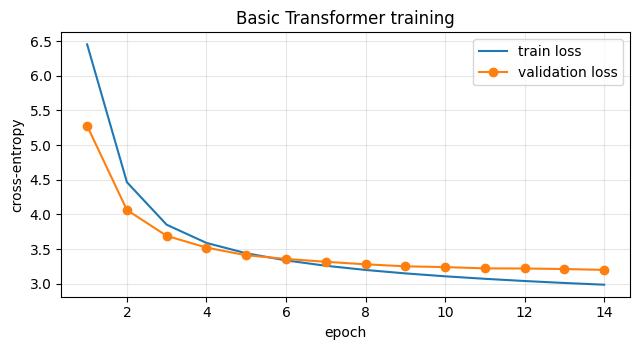

[20:08:26] [Basic Transformer] BLEU=23.01 chrF=51.77 infer=11.7s params=37,619,712
[20:08:28]   [Basic Transformer] T=0.0: BLEU=23.49 chrF=52.68
[20:08:30]   [Basic Transformer] T=0.2: BLEU=22.98 chrF=52.35
[20:08:32]   [Basic Transformer] T=0.5: BLEU=20.73 chrF=50.81
[20:08:35]   [Basic Transformer] T=0.8: BLEU=15.9 chrF=44.53
[20:08:38]   [Basic Transformer] T=1.0: BLEU=5.88 chrF=31.94
[20:08:42]   [Basic Transformer] T=1.2: BLEU=0.5 chrF=22.47
[20:08:43] ===== Stage 'transformer' finished in 77.0 min =====


In [12]:
import sentencepiece as spm

PAD, UNK, BOS, EOS = 0, 1, 2, 3


class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, dropout, max_len=1024):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0), persistent=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(x + self.pe[:, : x.size(1)].to(x.dtype))


class TransformerMT(nn.Module):
    def __init__(self, vocab, d_model, heads, n_enc, n_dec, d_ff, dropout):
        super().__init__()
        self.d_model = d_model
        self.embed = nn.Embedding(vocab, d_model, padding_idx=PAD)
        nn.init.normal_(self.embed.weight, mean=0.0, std=d_model ** -0.5)
        self.pos = SinusoidalPositionalEncoding(d_model, dropout)
        self.core = nn.Transformer(d_model=d_model, nhead=heads, num_encoder_layers=n_enc, num_decoder_layers=n_dec,
                                   dim_feedforward=d_ff, dropout=dropout, batch_first=True, norm_first=True)
        self.generator = nn.Linear(d_model, vocab, bias=False)
        self.generator.weight = self.embed.weight          # weight tying

    def _emb(self, ids):
        return self.pos(self.embed(ids) * math.sqrt(self.d_model))

    def encode(self, src):
        src_pad = src.eq(PAD)
        return self.core.encoder(self._emb(src), src_key_padding_mask=src_pad), src_pad

    def decode(self, tgt, memory, src_pad):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), diagonal=1)
        h = self.core.decoder(self._emb(tgt), memory, tgt_mask=causal, tgt_key_padding_mask=tgt.eq(PAD),
                              memory_key_padding_mask=src_pad)
        return self.generator(h)

    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src)
        return self.decode(tgt_in, memory, src_pad)


def train_sentencepiece(pairs, prefix, vocab_size):
    corpus = CKPT / f"{prefix}_corpus.txt"
    with open(corpus, "w") as fh:
        for s, t in pairs:
            fh.write(s + "\n" + t + "\n")
    spm.SentencePieceTrainer.train(
        input=str(corpus), model_prefix=str(CKPT / prefix), vocab_size=vocab_size, model_type="bpe",
        character_coverage=1.0, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
        input_sentence_size=1_000_000, shuffle_input_sentence=True, num_threads=os.cpu_count() or 2,
        minloglevel=2)
    return spm.SentencePieceProcessor(model_file=str(CKPT / f"{prefix}.model"))


def bucket_batches(lengths, batch_size, rng):
    idx = rng.permutation(len(lengths))
    pool = batch_size * 50
    batches = []
    for i in range(0, len(idx), pool):
        chunk = sorted(idx[i:i + pool], key=lambda j: lengths[j])
        batches += [chunk[k:k + batch_size] for k in range(0, len(chunk), batch_size)]
    rng.shuffle(batches)
    return batches


def pad_batch(seqs):
    L = max(len(s) for s in seqs)
    out = torch.full((len(seqs), L), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, : len(s)] = torch.tensor(s, dtype=torch.long)
    return out


def noam_lr(step, d_model, warmup):
    step = max(step, 1)
    return d_model ** -0.5 * min(step ** -0.5, step * warmup ** -1.5)


@torch.no_grad()
def tf_translate(model, sp, sents, temperature=0.0, batch_size=None):
    batch_size = batch_size or CFG["TF_DECODE_BATCH"]
    model.eval()
    results = [""] * len(sents)
    enc = sp.encode(list(sents))
    order = sorted(range(len(sents)), key=lambda i: len(enc[i]))
    for b in range(0, len(order), batch_size):
        ids = order[b:b + batch_size]
        src = pad_batch([enc[i][: CFG["TF_MAX_TOKENS"] - 1] + [EOS] for i in ids]).to(DEVICE)
        with amp():
            memory, src_pad = model.encode(src)
        ys = torch.full((len(ids), 1), BOS, dtype=torch.long, device=DEVICE)
        done = torch.zeros(len(ids), dtype=torch.bool, device=DEVICE)
        for _ in range(int(src.size(1) * 1.5) + 10):
            with amp():
                logits = model.decode(ys, memory, src_pad)[:, -1, :].float()
            logits[:, PAD] = -1e9
            if temperature and temperature > 0:
                nxt = torch.multinomial(torch.softmax(logits / temperature, dim=-1), 1).squeeze(1)
            else:
                nxt = logits.argmax(-1)
            nxt = torch.where(done, torch.full_like(nxt, PAD), nxt)
            ys = torch.cat([ys, nxt.unsqueeze(1)], dim=1)
            done |= nxt.eq(EOS)
            if bool(done.all()):
                break
        for row, i in zip(ys.tolist(), ids):
            toks = []
            for t in row[1:]:
                if t in (EOS, PAD):
                    break
                toks.append(t)
            results[i] = sp.decode(toks)
    return results


def stage_transformer():
    set_seed()
    t_train0 = time.time()
    sp = train_sentencepiece(TRAIN, "spm_joint_en_de", CFG["TF_VOCAB"])
    log(f"SentencePiece vocab = {sp.get_piece_size()}")
    fertility_entry("Basic Transformer", sp.encode)

    src_ids = sp.encode([s for s, _ in TRAIN])
    tgt_ids = sp.encode([t for _, t in TRAIN])
    M = CFG["TF_MAX_TOKENS"]
    src_ids = [x[: M - 1] + [EOS] for x in src_ids]
    tgt_ids = [[BOS] + x[: M - 2] + [EOS] for x in tgt_ids]
    lengths = [max(len(a), len(b)) for a, b in zip(src_ids, tgt_ids)]
    v_src = [x[: M - 1] + [EOS] for x in sp.encode([s for s, _ in VALID])]
    v_tgt = [[BOS] + x[: M - 2] + [EOS] for x in sp.encode([t for _, t in VALID])]

    model = TransformerMT(sp.get_piece_size(), CFG["TF_D_MODEL"], CFG["TF_HEADS"], CFG["TF_ENC_LAYERS"],
                          CFG["TF_DEC_LAYERS"], CFG["TF_FF"], CFG["TF_DROPOUT"]).to(DEVICE)
    n_params = count_params(model)
    log(f"Basic Transformer parameters: {n_params:,}")
    runner = nn.DataParallel(model) if N_GPU > 1 else model
    optim = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
    sched = torch.optim.lr_scheduler.LambdaLR(optim, lambda s: noam_lr(s + 1, CFG["TF_D_MODEL"], CFG["TF_WARMUP"]))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_CUDA)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=CFG["TF_LABEL_SMOOTHING"])
    rng = np.random.default_rng(CFG["SEED"])

    budget = CFG["TF_TIME_BUDGET_MIN"] * 60
    loop_start = time.time()
    history, best_bleu, best_state, step, stop = [], -1.0, None, 0, False
    vs, vr = [s for s, _ in VALID][: CFG["N_VALID_BLEU"]], [t for _, t in VALID][: CFG["N_VALID_BLEU"]]

    for epoch in range(1, CFG["TF_EPOCHS"] + 1):
        runner.train()
        losses = []
        for batch in bucket_batches(lengths, CFG["TF_BATCH"], rng):
            src = pad_batch([src_ids[i] for i in batch]).to(DEVICE)
            tgt = pad_batch([tgt_ids[i] for i in batch]).to(DEVICE)
            with amp():
                logits = runner(src, tgt[:, :-1])
            loss = criterion(logits.float().reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
            optim.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optim)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optim); scaler.update(); sched.step()
            losses.append(loss.item()); step += 1
            if step % 500 == 0:
                log(f"  epoch {epoch} step {step} loss {np.mean(losses[-500:]):.3f} lr {sched.get_last_lr()[0]:.2e}")
            if time.time() - loop_start > budget:
                stop = True
                break
        # validation
        model.eval()
        with torch.no_grad():
            v_losses = []
            for b in range(0, len(v_src), CFG["TF_BATCH"]):
                s = pad_batch(v_src[b:b + CFG["TF_BATCH"]]).to(DEVICE)
                t = pad_batch(v_tgt[b:b + CFG["TF_BATCH"]]).to(DEVICE)
                with amp():
                    lg = model(s, t[:, :-1])
                v_losses.append(criterion(lg.float().reshape(-1, lg.size(-1)), t[:, 1:].reshape(-1)).item())
        v_bleu = sacrebleu.corpus_bleu(tf_translate(model, sp, vs), [vr]).score
        history.append(dict(epoch=epoch, train_loss=float(np.mean(losses)), val_loss=float(np.mean(v_losses)),
                            val_bleu=round(v_bleu, 2), steps=step, minutes=round((time.time() - loop_start) / 60, 1)))
        log(f"Epoch {epoch}: train {history[-1]['train_loss']:.3f} | val {history[-1]['val_loss']:.3f} | val BLEU {v_bleu:.2f}")
        if v_bleu > best_bleu:
            best_bleu = v_bleu
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if stop:
            log("Time budget reached, stopping training.")
            break
    model.load_state_dict(best_state)
    train_time = time.time() - t_train0
    plot_history(history, "transformer", "Basic Transformer training", xlabel="epoch")

    fn = lambda sents, temp: tf_translate(model, sp, sents, temperature=temp)
    hyps, infer_t, mem = timed_translate(fn, TEST_SRC)
    record_result("transformer", "Basic Transformer", "Encoder-decoder", "Trained from scratch",
                  hyps, n_params, n_params, train_time, infer_t, mem,
                  extra=dict(epochs_completed=len(history), best_val_bleu=round(best_bleu, 2), train_pairs=len(TRAIN),
                             vocab=sp.get_piece_size(), pretrained=False))
    temperature_sweep("transformer", "Basic Transformer", fn)
    run_probes("transformer", "Basic Transformer", fn)
    del model, runner, optim, best_state


run_stage("transformer", stage_transformer)

## 4. Model 2: mT5-small (encoder-decoder, pretrained, full fine-tuning)

mT5 is the multilingual T5 model pretrained on the mC4 corpus covering 101 languages with a span-corruption objective. It has never seen a translation objective, so every weight is fine-tuned on the parallel data with the task prefix `translate English to German:`.

* 60,000 training pairs, 2 epochs, batch 16 (split over both GPUs), Adafactor with a constant learning rate of 1e-3 (the standard T5 recipe).
* **float32 training:** mT5 is known to overflow in float16 (NaN loss), and T4 GPUs have no bfloat16, so full precision is used.

[20:08:47] ===== Stage 'mt5' started =====


tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/1.20G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

[20:09:22] mT5 parameters: 300,176,768


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


[20:11:57]   mT5 epoch 1 step 250 loss 4.918
[20:14:25]   mT5 epoch 1 step 500 loss 3.701
[20:16:52]   mT5 epoch 1 step 750 loss 3.434
[20:19:21]   mT5 epoch 1 step 1000 loss 3.331
[20:21:47]   mT5 epoch 1 step 1250 loss 3.238
[20:24:14]   mT5 epoch 1 step 1500 loss 3.143
[20:26:44]   mT5 epoch 1 step 1750 loss 3.095
[20:29:10]   mT5 epoch 1 step 2000 loss 3.050
[20:31:37]   mT5 epoch 1 step 2250 loss 2.964
[20:34:05]   mT5 epoch 1 step 2500 loss 2.968
[20:36:33]   mT5 epoch 1 step 2750 loss 2.949
[20:39:02]   mT5 epoch 1 step 3000 loss 2.892
[20:41:29]   mT5 epoch 1 step 3250 loss 2.902
[20:43:57]   mT5 epoch 1 step 3500 loss 2.834
[20:46:23]   mT5 epoch 1 step 3750 loss 2.833
[20:46:35] mT5 epoch 1: train 3.217 | val 2.304 | val BLEU 11.14
[20:49:05]   mT5 epoch 2 step 4000 loss 2.581
[20:51:35]   mT5 epoch 2 step 4250 loss 2.606
[20:54:01]   mT5 epoch 2 step 4500 loss 2.555
[20:56:30]   mT5 epoch 2 step 4750 loss 2.582
[20:58:57]   mT5 epoch 2 step 5000 loss 2.557
[21:01:24]   mT5 e

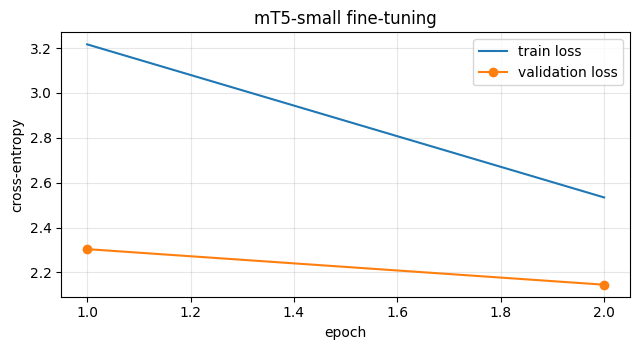

[21:24:00] [mT5-small] BLEU=16.6 chrF=44.85 infer=16.3s params=300,176,768
[21:24:06]   [mT5-small] T=0.0: BLEU=18.42 chrF=46.57
[21:24:11]   [mT5-small] T=0.2: BLEU=17.67 chrF=46.17
[21:24:16]   [mT5-small] T=0.5: BLEU=14.67 chrF=42.75
[21:24:21]   [mT5-small] T=0.8: BLEU=10.44 chrF=37.73
[21:24:26]   [mT5-small] T=1.0: BLEU=5.6 chrF=30.95
[21:24:33]   [mT5-small] T=1.2: BLEU=2.27 chrF=23.31
[21:24:33] ===== Stage 'mt5' finished in 75.8 min =====


In [13]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
from transformers.optimization import Adafactor


@torch.no_grad()
def mt5_translate(model, tok, sents, temperature=0.0):
    model.eval()
    results = [""] * len(sents)
    order = sorted(range(len(sents)), key=lambda i: len(sents[i]))
    bs = CFG["MT5_GEN_BATCH"]
    for b in range(0, len(order), bs):
        ids = order[b:b + bs]
        enc = tok([CFG["MT5_PREFIX"] + sents[i] for i in ids], return_tensors="pt", padding=True,
                  truncation=True, max_length=CFG["MT5_MAX_LEN"]).to(DEVICE)
        kwargs = dict(max_new_tokens=CFG["MT5_MAX_LEN"] + 32, num_beams=1)
        if temperature and temperature > 0:
            kwargs.update(do_sample=True, temperature=float(temperature), top_k=0, top_p=1.0)
        else:
            kwargs.update(do_sample=False)
        out = model.generate(**enc, **kwargs)
        for i, text in zip(ids, tok.batch_decode(out, skip_special_tokens=True)):
            results[i] = text.strip()
    return results


def stage_mt5():
    set_seed()
    t_train0 = time.time()
    tok = AutoTokenizer.from_pretrained(CFG["MT5_ID"])
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["MT5_ID"], torch_dtype=torch.float32).to(DEVICE)
    n_params = count_params(model)
    fertility_entry("mT5-small", lambda t: tok(t, add_special_tokens=False).input_ids)
    log(f"mT5 parameters: {n_params:,}")
    runner = nn.DataParallel(model) if N_GPU > 1 else model

    data = TRAIN[: CFG["N_TRAIN_MT5"]]
    optim = Adafactor(model.parameters(), lr=CFG["MT5_LR"], scale_parameter=False, relative_step=False, warmup_init=False)
    budget, loop_start = CFG["MT5_TIME_BUDGET_MIN"] * 60, time.time()
    rng = np.random.default_rng(CFG["SEED"])
    history, best_bleu, best_state, step, stop = [], -1.0, None, 0, False
    vs, vr = [s for s, _ in VALID][: CFG["N_VALID_BLEU"]], [t for _, t in VALID][: CFG["N_VALID_BLEU"]]

    def collate(pairs):
        enc = tok([CFG["MT5_PREFIX"] + s for s, _ in pairs], max_length=CFG["MT5_MAX_LEN"], truncation=True,
                  padding=True, return_tensors="pt")
        lab = tok(text_target=[t for _, t in pairs], max_length=CFG["MT5_MAX_LEN"], truncation=True,
                  padding=True, return_tensors="pt").input_ids
        lab[lab == tok.pad_token_id] = -100
        enc["labels"] = lab
        return {k: v.to(DEVICE) for k, v in enc.items()}

    lengths = [len(s) for s, _ in data]
    for epoch in range(1, CFG["MT5_EPOCHS"] + 1):
        runner.train()
        losses = []
        for batch in bucket_batches(lengths, CFG["MT5_BATCH"], rng):
            out = runner(**collate([data[i] for i in batch]), use_cache=False)
            loss = out.loss.mean()
            optim.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()
            losses.append(loss.item()); step += 1
            if step % 250 == 0:
                log(f"  mT5 epoch {epoch} step {step} loss {np.mean(losses[-250:]):.3f}")
            if time.time() - loop_start > budget:
                stop = True
                break
        model.eval()
        with torch.no_grad():
            v_losses = [model(**collate(VALID[b:b + 32])).loss.item() for b in range(0, min(len(VALID), 512), 32)]
        v_bleu = sacrebleu.corpus_bleu(mt5_translate(model, tok, vs), [vr]).score
        history.append(dict(epoch=epoch, train_loss=float(np.mean(losses)), val_loss=float(np.mean(v_losses)),
                            val_bleu=round(v_bleu, 2), steps=step))
        log(f"mT5 epoch {epoch}: train {history[-1]['train_loss']:.3f} | val {history[-1]['val_loss']:.3f} | val BLEU {v_bleu:.2f}")
        if v_bleu > best_bleu:
            best_bleu = v_bleu
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if stop:
            log("Time budget reached, stopping mT5 training.")
            break
    model.load_state_dict(best_state)
    train_time = time.time() - t_train0
    plot_history(history, "mt5", "mT5-small fine-tuning", xlabel="epoch")

    fn = lambda sents, temp: mt5_translate(model, tok, sents, temperature=temp)
    hyps, infer_t, mem = timed_translate(fn, TEST_SRC)
    record_result("mt5", "mT5-small", "Encoder-decoder", "Full fine-tuning", hyps, n_params, n_params,
                  train_time, infer_t, mem,
                  extra=dict(epochs_completed=len(history), best_val_bleu=round(best_bleu, 2), train_pairs=len(data),
                             vocab=len(tok), pretrained=True))
    temperature_sweep("mt5", "mT5-small", fn)
    run_probes("mt5", "mT5-small", fn)
    del model, runner, optim, best_state


run_stage("mt5", stage_mt5)

## 5. Decoder-only models: shared prompting and LoRA code

Decoder-only models translate by continuing a prompt. Each instruction-tuned model receives the same user message through its own chat template:

> Translate the following English sentence into German. Reply with only the German translation.
> English: *source sentence*

**Zero-shot prompting** uses this prompt with no training. **LoRA fine-tuning** then trains low-rank adapter matrices on the attention (and for LLaMA also the MLP) projections while the original weights stay frozen. The loss is computed **only on the German answer tokens**; prompt tokens are masked with -100. Both modes use greedy decoding and the same stop tokens, so they are directly comparable with the encoder-decoder models.

In [14]:
from peft import LoraConfig, get_peft_model
from transformers import AutoTokenizer, AutoModelForCausalLM   # imported here too so this section runs on its own

LLM_INSTRUCTION = ("Translate the following {src} sentence into {tgt}. Reply with only the {tgt} translation.\n\n"
                   "{src}: {text}")


def user_message(text):
    return LLM_INSTRUCTION.format(src=CFG["SRC_NAME"], tgt=CFG["TGT_NAME"], text=text)


def chat_prompt(tok, text):
    return tok.apply_chat_template([{"role": "user", "content": user_message(text)}], tokenize=False,
                                   add_generation_prompt=True)


def chat_full(tok, text, answer):
    return tok.apply_chat_template([{"role": "user", "content": user_message(text)},
                                    {"role": "assistant", "content": answer}], tokenize=False)


def build_sft_example(tok, src, tgt):
    prompt = chat_prompt(tok, src)
    full = chat_full(tok, src, tgt)
    if full.startswith(prompt):
        answer_part = full[len(prompt):]
    else:  # fall back if a template re-renders the prefix differently
        answer_part = tgt + (tok.eos_token or "")
    p_ids = tok(prompt, add_special_tokens=False).input_ids
    a_ids = tok(answer_part, add_special_tokens=False).input_ids
    ids = (p_ids + a_ids)[: CFG["LLM_MAX_LEN"]]
    labels = ([-100] * len(p_ids) + a_ids)[: CFG["LLM_MAX_LEN"]]
    return ids, labels


def stop_token_ids(tok, model):
    ids = set()
    for t in [tok.eos_token, "<|eot_id|>", "<|end_of_text|>", "<end_of_turn>", "<eos>"]:
        if t and t in tok.get_vocab():
            ids.add(tok.convert_tokens_to_ids(t))
    gen_eos = getattr(model.generation_config, "eos_token_id", None)
    if isinstance(gen_eos, int):
        ids.add(gen_eos)
    elif isinstance(gen_eos, (list, tuple)):
        ids.update(gen_eos)
    return sorted(ids)


def clean_llm_output(text):
    text = text.strip()
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    text = lines[0] if lines else ""
    text = re.sub(rf"^(\*\*)?({CFG['TGT_NAME']}|Deutsch|Translation|Übersetzung)(\*\*)?\s*:\s*", "", text, flags=re.I)
    if len(text) > 1 and text[0] in "\"'«„“" and text[-1] in "\"'»“”":
        text = text[1:-1]
    return text.strip()


def input_device(model):
    return model.get_input_embeddings().weight.device


@torch.no_grad()
def llm_translate(model, tok, sents, temperature=0.0, batch_size=16, use_amp=True):
    model.eval()
    tok.padding_side = "left"
    stops = stop_token_ids(tok, model)
    dev = input_device(model)
    prompts = [chat_prompt(tok, s) for s in sents]
    order = sorted(range(len(sents)), key=lambda i: len(prompts[i]))
    results = [""] * len(sents)
    for b in range(0, len(order), batch_size):
        ids = order[b:b + batch_size]
        enc = tok([prompts[i] for i in ids], return_tensors="pt", padding=True, add_special_tokens=False,
                  return_token_type_ids=False).to(dev)
        kwargs = dict(max_new_tokens=CFG["LLM_MAX_NEW_TOKENS"], eos_token_id=stops, pad_token_id=tok.pad_token_id,
                      use_cache=True)
        if temperature and temperature > 0:
            kwargs.update(do_sample=True, temperature=float(temperature), top_k=0, top_p=1.0)
        else:
            kwargs.update(do_sample=False, temperature=None, top_k=None, top_p=None)
        with amp(use_amp):
            out = model.generate(**enc, **kwargs)
        texts = tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for i, t in zip(ids, texts):
            results[i] = clean_llm_output(t)
    return results


def lora_finetune(model, tok, pairs, r, targets, lr, micro_batch, accum, epochs, budget_min, use_amp, tag):
    """Generic LoRA supervised fine-tuning loop with answer-only loss."""
    model.config.use_cache = False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    cfg = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05, target_modules=targets, bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(model, cfg)
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    model.print_trainable_parameters()

    examples = [build_sft_example(tok, s, t) for s, t in pairs]
    log(f"[{tag}] {len(examples)} SFT examples, mean length {np.mean([len(e[0]) for e in examples]):.1f} tokens")
    params = [p for p in model.parameters() if p.requires_grad]
    optim = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    steps_total = max(1, math.ceil(len(examples) / (micro_batch * accum)) * epochs)
    sched = torch.optim.lr_scheduler.LambdaLR(
        optim, lambda s: min(1.0, (s + 1) / max(1, int(0.05 * steps_total))) * max(0.0, 1 - s / steps_total))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_CUDA and use_amp)
    dev = input_device(model)
    pad_id = tok.pad_token_id
    rng = np.random.default_rng(CFG["SEED"])
    budget, start = budget_min * 60, time.time()
    history, step, micro, run_loss, stop = [], 0, 0, [], False
    model.train()
    for epoch in range(epochs):
        for batch in bucket_batches([len(e[0]) for e in examples], micro_batch, rng):
            L = max(len(examples[i][0]) for i in batch)
            ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
            lab = torch.full((len(batch), L), -100, dtype=torch.long)
            att = torch.zeros((len(batch), L), dtype=torch.long)
            for j, i in enumerate(batch):
                x, y = examples[i]
                ids[j, : len(x)] = torch.tensor(x); lab[j, : len(y)] = torch.tensor(y); att[j, : len(x)] = 1
            with amp(use_amp):
                loss = model(input_ids=ids.to(dev), attention_mask=att.to(dev), labels=lab.to(dev)).loss
            scaler.scale(loss / accum).backward()
            run_loss.append(loss.item()); micro += 1
            if micro % accum == 0:
                scaler.unscale_(optim)
                nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(optim); scaler.update(); optim.zero_grad(set_to_none=True); sched.step()
                step += 1
                if step % 25 == 0:
                    history.append(dict(step=step, train_loss=float(np.mean(run_loss[-25 * accum:]))))
                    log(f"  [{tag}] step {step}/{steps_total} loss {history[-1]['train_loss']:.3f}")
            if time.time() - start > budget:
                stop = True
                break
        if stop:
            log(f"[{tag}] time budget reached after {step} optimiser steps.")
            break
    model.gradient_checkpointing_disable()
    model.config.use_cache = True
    model.eval()
    return model, history, step, steps_total


def run_decoder_only(prefix, display, model_id, dtype_name, device_map, attn_impl, n_train, r, targets, lr,
                     micro_batch, accum, epochs, budget, gen_batch):
    set_seed()
    dtype = getattr(torch, dtype_name)
    use_amp = dtype == torch.float16
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    load_kwargs = dict(torch_dtype=dtype)
    if attn_impl:
        load_kwargs["attn_implementation"] = attn_impl
    if USE_CUDA and device_map:
        load_kwargs["device_map"] = device_map
    t_load = time.time()
    model = AutoModelForCausalLM.from_pretrained(model_id, **load_kwargs)
    if not (USE_CUDA and device_map):
        model.to(DEVICE)
    load_time = time.time() - t_load
    n_params = count_params(model)
    fertility_entry(display, lambda t: tok(t, add_special_tokens=False).input_ids)
    log(f"{display}: {n_params:,} parameters, loaded in {load_time:.0f}s")

    fn = lambda sents, temp: llm_translate(model, tok, sents, temperature=temp, batch_size=gen_batch, use_amp=use_amp)
    # (a) zero-shot prompting
    hyps, infer_t, mem = timed_translate(fn, TEST_SRC)
    record_result(f"{prefix}_zeroshot", f"{display} (zero-shot)", "Decoder-only", "Zero-shot prompting",
                  hyps, n_params, 0, None, infer_t, mem, extra=dict(train_pairs=0, pretrained=True, vocab=len(tok)))
    run_probes(f"{prefix}_zeroshot", f"{display} (zero-shot)", fn)

    # (b) LoRA fine-tuning
    t0 = time.time()
    model, history, steps_done, steps_total = lora_finetune(
        model, tok, TRAIN[:n_train], r, targets, lr, micro_batch, accum, epochs, budget, use_amp, display)
    train_time = time.time() - t0
    n_trainable = count_params(model, trainable_only=True)
    plot_history(history, prefix, f"{display} LoRA fine-tuning")
    fn = lambda sents, temp: llm_translate(model, tok, sents, temperature=temp, batch_size=gen_batch, use_amp=use_amp)
    hyps, infer_t, mem = timed_translate(fn, TEST_SRC)
    record_result(f"{prefix}_lora", f"{display} + LoRA", "Decoder-only", f"LoRA fine-tuning (r={r})",
                  hyps, n_params, n_trainable, train_time, infer_t, mem,
                  extra=dict(train_pairs=n_train, lora_steps=steps_done, lora_steps_planned=steps_total,
                             pretrained=True, vocab=len(tok)))
    temperature_sweep(f"{prefix}_lora", f"{display} + LoRA", fn)
    run_probes(f"{prefix}_lora", f"{display} + LoRA", fn)
    model.save_pretrained(CKPT / f"{prefix}_lora_adapter")
    del model

## 6. Model 3: LLaMA 3.2 1B Instruct (decoder-only)

* 1.24B parameters, 128K-token BPE vocabulary, officially supports English and German.
* float16 weights on a single T4. LoRA rank 16 on all attention and MLP projections (about 11M trainable parameters, under 1% of the model), learning rate 2e-4 with warm-up and linear decay, effective batch 16, 12,000 pairs, 1 epoch.

[21:24:34] ===== Stage 'llama' started =====


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/877 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.47G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

[21:24:52] LLaMA-3.2-1B-Instruct: 1,235,814,400 parameters, loaded in 16s
[21:25:59] [LLaMA-3.2-1B-Instruct (zero-shot)] BLEU=18.68 chrF=46.45 infer=65.6s params=1,235,814,400
trainable params: 11,272,192 || all params: 1,247,086,592 || trainable%: 0.9039
[21:26:07] [LLaMA-3.2-1B-Instruct] 12000 SFT examples, mean length 120.1 tokens
[21:26:37]   [LLaMA-3.2-1B-Instruct] step 25/750 loss 1.802
[21:27:05]   [LLaMA-3.2-1B-Instruct] step 50/750 loss 1.663
[21:27:35]   [LLaMA-3.2-1B-Instruct] step 75/750 loss 1.607
[21:28:02]   [LLaMA-3.2-1B-Instruct] step 100/750 loss 1.525
[21:28:34]   [LLaMA-3.2-1B-Instruct] step 125/750 loss 1.631
[21:29:02]   [LLaMA-3.2-1B-Instruct] step 150/750 loss 1.557
[21:29:32]   [LLaMA-3.2-1B-Instruct] step 175/750 loss 1.598
[21:30:00]   [LLaMA-3.2-1B-Instruct] step 200/750 loss 1.624
[21:30:28]   [LLaMA-3.2-1B-Instruct] step 225/750 loss 1.532
[21:30:59]   [LLaMA-3.2-1B-Instruct] step 250/750 loss 1.512
[21:31:28]   [LLaMA-3.2-1B-Instruct] step 275/750 loss 1.

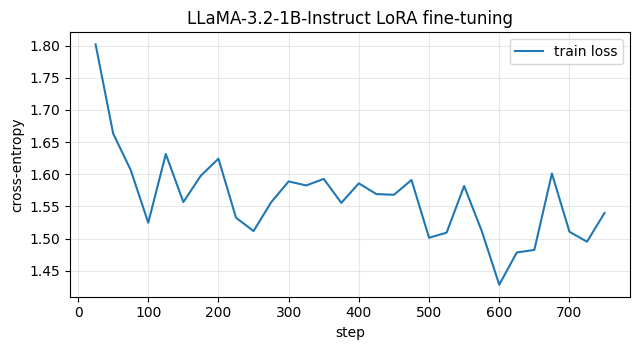

[21:42:20] [LLaMA-3.2-1B-Instruct + LoRA] BLEU=21.84 chrF=50.72 infer=101.8s params=1,235,814,400
[21:42:44]   [LLaMA-3.2-1B-Instruct + LoRA] T=0.0: BLEU=23.62 chrF=52.74
[21:43:08]   [LLaMA-3.2-1B-Instruct + LoRA] T=0.2: BLEU=22.47 chrF=51.31
[21:43:31]   [LLaMA-3.2-1B-Instruct + LoRA] T=0.5: BLEU=18.8 chrF=48.21
[21:44:07]   [LLaMA-3.2-1B-Instruct + LoRA] T=0.8: BLEU=11.15 chrF=39.83
[21:45:03]   [LLaMA-3.2-1B-Instruct + LoRA] T=1.0: BLEU=4.71 chrF=30.08
[21:46:12]   [LLaMA-3.2-1B-Instruct + LoRA] T=1.2: BLEU=0.37 chrF=16.88
[21:46:15] ===== Stage 'llama' finished in 21.7 min =====


In [15]:
def stage_llama():
    run_decoder_only("llama", "LLaMA-3.2-1B-Instruct", CFG["LLAMA_ID"], CFG["LLAMA_DTYPE"], {"": 0}, "sdpa",
                     CFG["N_TRAIN_LLAMA"], CFG["LLAMA_LORA_R"], CFG["LLAMA_LORA_TARGETS"], CFG["LLAMA_LR"],
                     CFG["LLAMA_MICRO_BATCH"], CFG["LLAMA_ACCUM"], CFG["LLAMA_EPOCHS"], CFG["LLAMA_TIME_BUDGET_MIN"],
                     CFG["LLAMA_GEN_BATCH"])


run_stage("llama", stage_llama)

## 7. Model 4: Gemma 2 2B Instruct (decoder-only)

* 2.61B parameters, 256K-token SentencePiece vocabulary, multilingual pretraining.
* Gemma's activations exceed the float16 range, so the model runs in **float32** and is **sharded across both T4 GPUs** (`device_map="auto"`), which is where the second GPU pays off. Eager attention is used as recommended for Gemma 2 (logit soft-capping).
* LoRA rank 8 on the attention projections, learning rate 2e-4, effective batch 16, 6,000 pairs (fewer than LLaMA because float32 training of a 2.6B model is slower).

[21:46:15] ===== Stage 'gemma' started =====


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

...

model-00001-of-00002.safetensors:   0%|          | 0.00/4.99G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/241M [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

[21:46:50] Gemma-2-2B-it: 2,614,341,888 parameters, loaded in 32s
[21:51:38] [Gemma-2-2B-it (zero-shot)] BLEU=27.66 chrF=56.65 infer=287.6s params=2,614,341,888
trainable params: 3,194,880 || all params: 2,617,536,768 || trainable%: 0.1221
[21:51:49] [Gemma-2-2B-it] 6000 SFT examples, mean length 87.6 tokens
[21:54:51]   [Gemma-2-2B-it] step 25/375 loss 2.081
[21:57:48]   [Gemma-2-2B-it] step 50/375 loss 1.620
[22:00:43]   [Gemma-2-2B-it] step 75/375 loss 1.660
[22:03:50]   [Gemma-2-2B-it] step 100/375 loss 1.583
[22:06:56]   [Gemma-2-2B-it] step 125/375 loss 1.489
[22:09:48]   [Gemma-2-2B-it] step 150/375 loss 1.510
[22:12:51]   [Gemma-2-2B-it] step 175/375 loss 1.482
[22:15:57]   [Gemma-2-2B-it] step 200/375 loss 1.566
[22:19:01]   [Gemma-2-2B-it] step 225/375 loss 1.563
[22:22:00]   [Gemma-2-2B-it] step 250/375 loss 1.475
[22:25:00]   [Gemma-2-2B-it] step 275/375 loss 1.465
[22:27:55]   [Gemma-2-2B-it] step 300/375 loss 1.506
[22:30:52]   [Gemma-2-2B-it] step 325/375 loss 1.529
[22:

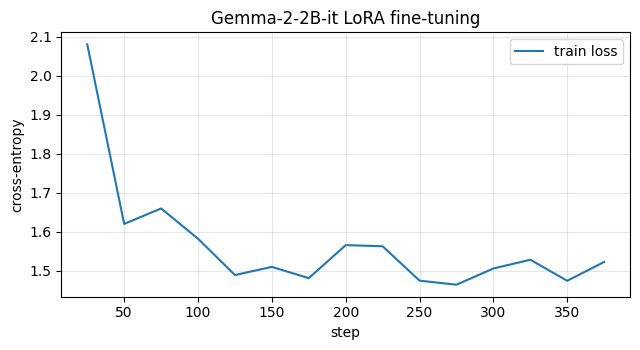

[22:41:39] [Gemma-2-2B-it + LoRA] BLEU=28.62 chrF=56.44 infer=299.0s params=2,614,341,888
[22:42:45]   [Gemma-2-2B-it + LoRA] T=0.0: BLEU=29.32 chrF=57.03
[22:43:51]   [Gemma-2-2B-it + LoRA] T=0.2: BLEU=29.91 chrF=57.39
[22:45:00]   [Gemma-2-2B-it + LoRA] T=0.5: BLEU=24.74 chrF=53.78
[22:46:17]   [Gemma-2-2B-it + LoRA] T=0.8: BLEU=14.73 chrF=44.27
[22:47:42]   [Gemma-2-2B-it + LoRA] T=1.0: BLEU=8.54 chrF=34.56
[22:50:32]   [Gemma-2-2B-it + LoRA] T=1.2: BLEU=2.43 chrF=23.73
[22:50:40] ===== Stage 'gemma' finished in 64.4 min =====


In [ ]:
def stage_gemma():
    run_decoder_only("gemma", "Gemma-2-2B-it", CFG["GEMMA_ID"], CFG["GEMMA_DTYPE"], "auto", "eager",
                     CFG["N_TRAIN_GEMMA"], CFG["GEMMA_LORA_R"], CFG["GEMMA_LORA_TARGETS"], CFG["GEMMA_LR"],
                     CFG["GEMMA_MICRO_BATCH"], CFG["GEMMA_ACCUM"], CFG["GEMMA_EPOCHS"], CFG["GEMMA_TIME_BUDGET_MIN"],
                     CFG["GEMMA_GEN_BATCH"])


run_stage("gemma", stage_gemma)

## 8. Evaluation and comparison
All metrics are loaded back from disk, so this section also works if the model stages were run in separate sessions.

In [ ]:
MODEL_ORDER = ["transformer", "mt5", "llama_zeroshot", "llama_lora", "gemma_zeroshot", "gemma_lora"]
MAIN_FOUR = ["transformer", "mt5", "llama_lora", "gemma_lora"]

METRICS = {k: load_json(DIRS["metrics"] / f"{k}.json") for k in MODEL_ORDER if (DIRS["metrics"] / f"{k}.json").exists()}
PREDS = {k: (DIRS["predictions"] / f"{k}.txt").read_text()[:-1].split("\n") for k in METRICS}
for f in DIRS["metrics"].glob("fertility_*.json"):
    TOKENIZER_FERTILITY[f.stem.replace("fertility_", "")] = load_json(f)
missing = [k for k in MODEL_ORDER if k not in METRICS]
if missing:
    print("WARNING: results missing for", missing, "(see logs/errors.log)")


def fmt_params(n):
    return f"{n / 1e9:.2f}B" if n >= 1e9 else f"{n / 1e6:.1f}M"


rows = []
for k, m in METRICS.items():
    rows.append({"Model": m["model"], "Architecture": m["architecture"], "Adaptation": m["adaptation"],
                 "BLEU": m["bleu"], "chrF": m["chrf"], "Total params": fmt_params(m["total_params"]),
                 "Trainable params": fmt_params(m["trainable_params"]) if m["trainable_params"] else "0",
                 "Train pairs": m.get("train_pairs", 0),
                 "Training time (min)": "N/A" if m["train_time_min"] is None else m["train_time_min"],
                 "Inference time (s)": m["infer_time_s"], "Sentences/s": m["sent_per_s"],
                 "Peak GPU mem (GB)": m["peak_gpu_mem_gb"]})
RESULTS_DF = pd.DataFrame(rows)
RESULTS_DF.to_csv(DIRS["metrics"] / "results_table.csv", index=False)
display_df = RESULTS_DF.copy()
print(display_df.to_string(index=False))

                            Model    Architecture              Adaptation  BLEU  chrF Total params Trainable params  Train pairs Training time (min)  Inference time (s)  Sentences/s  Peak GPU mem (GB)
                Basic Transformer Encoder-decoder    Trained from scratch 23.01 51.77        37.6M            37.6M       300000               76.46                11.7        85.41               1.75
                        mT5-small Encoder-decoder        Full fine-tuning 16.60 44.85       300.2M           300.2M        60000               74.94                16.3        61.19               3.05
LLaMA-3.2-1B-Instruct (zero-shot)    Decoder-only     Zero-shot prompting 18.68 46.45        1.24B                0            0                 N/A                65.6        15.25               2.71
     LLaMA-3.2-1B-Instruct + LoRA    Decoder-only LoRA fine-tuning (r=16) 21.84 50.72        1.24B            11.3M        12000               14.63               101.8         9.82               

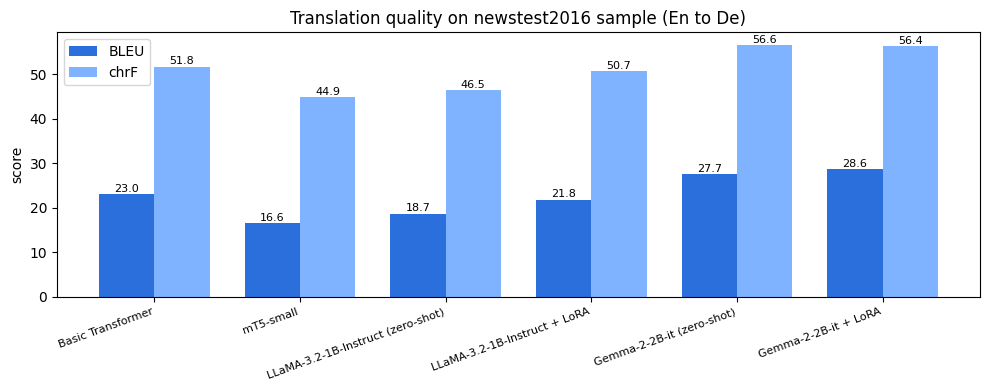

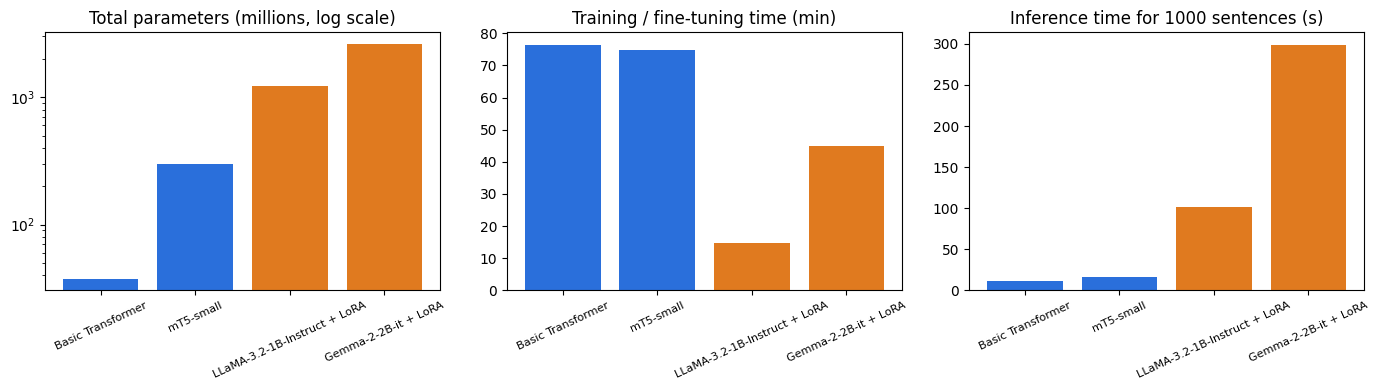

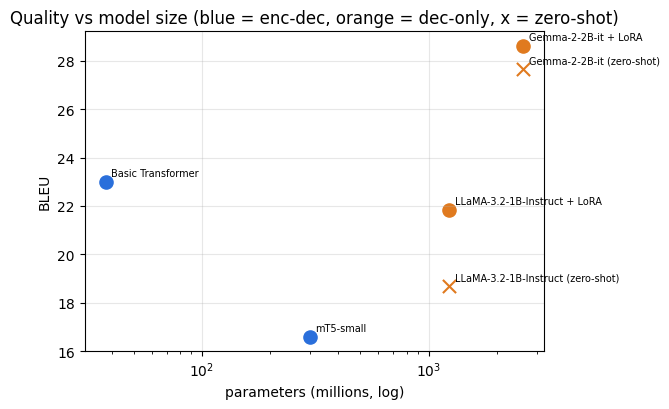

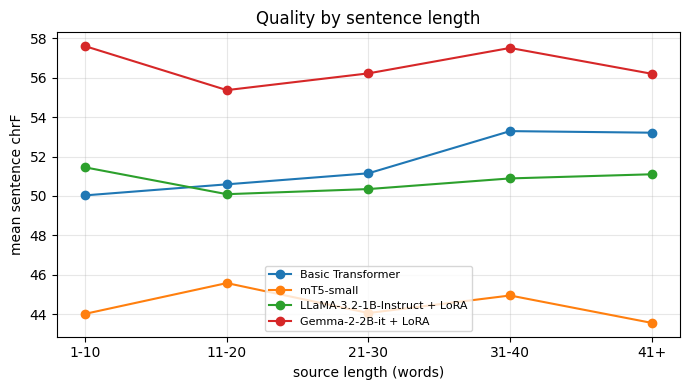

                       Model  1-10  11-20  21-30  31-40   41+
           Basic Transformer 50.03  50.59  51.15  53.29 53.21
                   mT5-small 44.02  45.58  44.06  44.95 43.56
LLaMA-3.2-1B-Instruct + LoRA 51.45  50.09  50.35  50.89 51.10
        Gemma-2-2B-it + LoRA 57.60  55.37  56.22  57.51 56.20


In [ ]:
# ---- plots ----
main = [k for k in MAIN_FOUR if k in METRICS]
allk = list(METRICS.keys())
colors = {"Encoder-decoder": "#2a6fdb", "Decoder-only": "#e07a1f"}

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(allk)); w = 0.38
ax.bar(x - w / 2, [METRICS[k]["bleu"] for k in allk], w, label="BLEU", color="#2a6fdb")
ax.bar(x + w / 2, [METRICS[k]["chrf"] for k in allk], w, label="chrF", color="#7fb3ff")
for i, k in enumerate(allk):
    ax.text(i - w / 2, METRICS[k]["bleu"] + 0.5, f"{METRICS[k]['bleu']:.1f}", ha="center", fontsize=8)
    ax.text(i + w / 2, METRICS[k]["chrf"] + 0.5, f"{METRICS[k]['chrf']:.1f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([METRICS[k]["model"] for k in allk], rotation=20, ha="right", fontsize=8)
ax.set_ylabel("score"); ax.set_title("Translation quality on newstest2016 sample (En to De)"); ax.legend()
plt.tight_layout(); plt.savefig(DIRS["plots"] / "quality_bleu_chrf.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
names = [METRICS[k]["model"] for k in main]
cols = [colors[METRICS[k]["architecture"]] for k in main]
axes[0].bar(names, [METRICS[k]["total_params"] / 1e6 for k in main], color=cols); axes[0].set_yscale("log")
axes[0].set_title("Total parameters (millions, log scale)")
axes[1].bar(names, [METRICS[k]["train_time_min"] or 0 for k in main], color=cols); axes[1].set_title("Training / fine-tuning time (min)")
axes[2].bar(names, [METRICS[k]["infer_time_s"] for k in main], color=cols); axes[2].set_title(f"Inference time for {len(TEST_SRC)} sentences (s)")
for ax in axes:
    ax.tick_params(axis="x", rotation=25, labelsize=8)
plt.tight_layout(); plt.savefig(DIRS["plots"] / "compute_comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for k in allk:
    m = METRICS[k]
    ax.scatter(m["total_params"] / 1e6, m["bleu"], s=90, color=colors[m["architecture"]],
               marker="o" if "zeroshot" not in k else "x")
    ax.annotate(m["model"], (m["total_params"] / 1e6, m["bleu"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("parameters (millions, log)"); ax.set_ylabel("BLEU")
ax.set_title("Quality vs model size (blue = enc-dec, orange = dec-only, x = zero-shot)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(DIRS["plots"] / "bleu_vs_params.png", dpi=150); plt.show()

# sentence-level chrF by source length
buckets = [(1, 10), (11, 20), (21, 30), (31, 40), (41, 200)]
labels = ["1-10", "11-20", "21-30", "31-40", "41+"]
BUCKET_ROWS = []
fig, ax = plt.subplots(figsize=(7, 4))
for k in main:
    vals = []
    for lo, hi in buckets:
        idx = [i for i, s in enumerate(TEST_SRC) if lo <= len(s.split()) <= hi]
        v = np.mean([sacrebleu.sentence_chrf(PREDS[k][i], [TEST_REF[i]]).score for i in idx]) if idx else np.nan
        vals.append(round(float(v), 2))
    BUCKET_ROWS.append([METRICS[k]["model"]] + vals)
    ax.plot(labels, vals, marker="o", label=METRICS[k]["model"])
ax.set_xlabel("source length (words)"); ax.set_ylabel("mean sentence chrF"); ax.set_title("Quality by sentence length")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(DIRS["plots"] / "chrf_by_length.png", dpi=150); plt.show()
BUCKET_DF = pd.DataFrame(BUCKET_ROWS, columns=["Model"] + labels)
print(BUCKET_DF.to_string(index=False))

In [ ]:
# ---- sample translations ----
def md_escape(s):
    return s.replace("|", "\\|")


sample_idx = list(range(0, len(TEST_SRC), max(1, len(TEST_SRC) // 20)))[:20]
lines = ["# Sample translations (newstest2016, greedy decoding)\n"]
for i in sample_idx:
    lines.append(f"### Example {i}\n\n| System | Text |\n|---|---|")
    lines.append(f"| Source (EN) | {md_escape(TEST_SRC[i])} |")
    lines.append(f"| Reference (DE) | {md_escape(TEST_REF[i])} |")
    for k in allk:
        lines.append(f"| {METRICS[k]['model']} | {md_escape(PREDS[k][i])} |")
    lines.append("")
(DIRS["samples"] / "sample_translations.md").write_text("\n".join(lines))
pd.DataFrame({"source": TEST_SRC, "reference": TEST_REF, **{METRICS[k]["model"]: PREDS[k] for k in allk}}).to_csv(
    DIRS["samples"] / "all_test_translations.csv", index=False)
print("\n".join(lines[:30]))

# Sample translations (newstest2016, greedy decoding)

### Example 0

| System | Text |
|---|---|
| Source (EN) | In 911 Call, Professor Admits to Shooting Girlfriend |
| Reference (DE) | In einem Notruf gesteht Professor, seine Freundin erschossen zu haben |
| Basic Transformer | In 911 Call, Professor Admits to Shooting Girlfriends to Shooting Girlfriends. |
| mT5-small | In der Sofortwahl steht Professor Anfänger, dass er ihr Freunde auch schon entschuldigt. |
| LLaMA-3.2-1B-Instruct (zero-shot) | Professor Admits to Shooting Girlfriend |
| LLaMA-3.2-1B-Instruct + LoRA | In 911 Call, Professor Admits to Shooting Girlfriend |
| Gemma-2-2B-it (zero-shot) | In 911-Ruf gibt Professor zu, seine Freundin zu erschießen. |
| Gemma-2-2B-it + LoRA | In 911 Call, Professor Admits to Shooting Girlfriend |

### Example 50

| System | Text |
|---|---|
| Source (EN) | But Bayern, undefeated in seven Europa Cup duels with Greek teams, did not want to be the next victim. |
| Reference (DE) | Doch di

## 9. Sampling-temperature analysis
Temperature rescales the logits before sampling: T to 0 approaches greedy decoding, T = 1 samples from the model's raw distribution, T > 1 flattens it. For translation there is usually one correct meaning, so higher temperatures are expected to add lexical variety at the cost of adequacy.

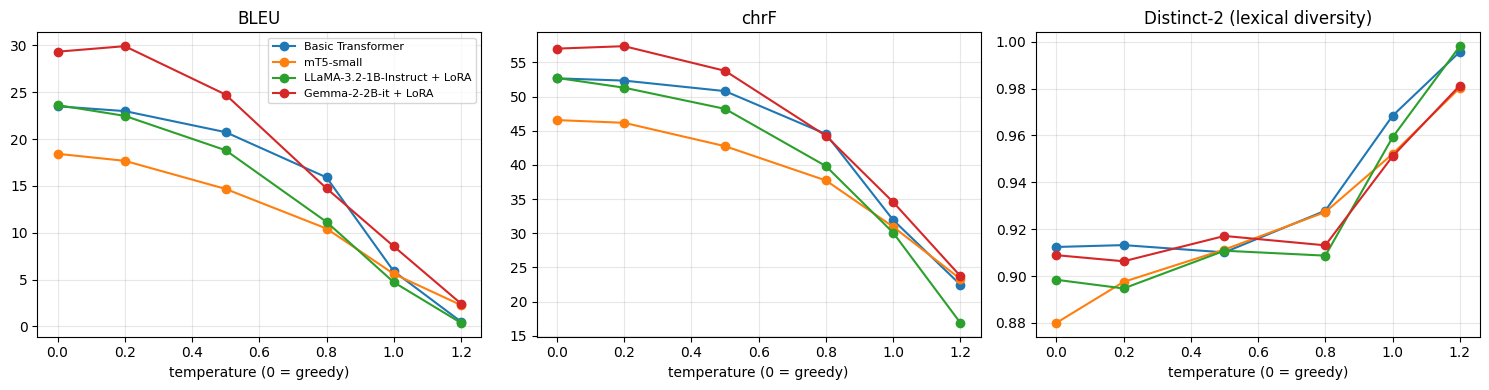

                       Model  Temperature  BLEU  chrF  Length ratio  Distinct-2  Abnormal length %
           Basic Transformer          0.0 23.49 52.68         0.959      0.9124                1.0
           Basic Transformer          0.2 22.98 52.35         0.963      0.9132                0.5
           Basic Transformer          0.5 20.73 50.81         0.971      0.9101                0.5
           Basic Transformer          0.8 15.90 44.53         1.013      0.9279                1.0
           Basic Transformer          1.0  5.88 31.94         1.043      0.9684                3.0
           Basic Transformer          1.2  0.50 22.47         1.378      0.9957               26.0
                   mT5-small          0.0 18.42 46.57         0.911      0.8800                0.5
                   mT5-small          0.2 17.67 46.17         0.888      0.8975                0.0
                   mT5-small          0.5 14.67 42.75         0.897      0.9113                0.0
          

2620

In [ ]:
TEMP = {k: load_json(DIRS["temperature"] / f"{k}.json") for k in MAIN_FOUR if (DIRS["temperature"] / f"{k}.json").exists()}
temp_rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for k, d in TEMP.items():
    df = pd.DataFrame(d["rows"])
    for _, r in df.iterrows():
        temp_rows.append({"Model": d["model"], "Temperature": r["temperature"], "BLEU": r["bleu"], "chrF": r["chrf"],
                          "Length ratio": r["length_ratio"], "Distinct-2": r["distinct_2"],
                          "Abnormal length %": r["abnormal_length_pct"]})
    axes[0].plot(df["temperature"], df["bleu"], marker="o", label=d["model"])
    axes[1].plot(df["temperature"], df["chrf"], marker="o", label=d["model"])
    axes[2].plot(df["temperature"], df["distinct_2"], marker="o", label=d["model"])
for ax, t in zip(axes, ["BLEU", "chrF", "Distinct-2 (lexical diversity)"]):
    ax.set_xlabel("temperature (0 = greedy)"); ax.set_title(t); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(DIRS["plots"] / "temperature_analysis.png", dpi=150); plt.show()
TEMP_DF = pd.DataFrame(temp_rows)
TEMP_DF.to_csv(DIRS["metrics"] / "temperature_table.csv", index=False)
print(TEMP_DF.to_string(index=False))

temp_lines = ["# Temperature samples (first test sentence)\n"]
for k, d in TEMP.items():
    temp_lines.append(f"## {d['model']}\n\nSource: {d['sources'][0]}\n\nReference: {d['references'][0]}\n")
    temp_lines.append("| T | Output |\n|---|---|")
    for t, outs in d["examples"].items():
        temp_lines.append(f"| {t} | {md_escape(outs[0])} |")
    temp_lines.append("")
(DIRS["samples"] / "temperature_samples.md").write_text("\n".join(temp_lines))

## 10. Responsible and ethical AI probes
Automatic flags (all heuristics, intended to direct manual review rather than replace it):
* **Gender form:** for occupation sentences with an unmarked English noun, which German form was chosen: masculine (M), feminine (F) or neither (N).
* **Numbers changed:** the digit sequences in the output differ from the source.
* **Names dropped:** a capitalised name in the source is missing from the output.
* **Length anomaly:** output/source word ratio below 0.5 or above 2.0 (omission or added content).
* **Untranslated:** the output is almost identical to the English source.
* **Meta text:** the output contains English commentary such as "Here is", "I cannot" or "Note:".
* **Formality:** whether the polite *Sie* or informal *du* form was chosen for the direct request (C5).

In [ ]:
ETH = {k: load_json(DIRS["ethics"] / f"{k}.json") for k in MODEL_ORDER if (DIRS["ethics"] / f"{k}.json").exists()}
META_PAT = re.compile(r"\b(here is|here's|i cannot|i can't|i'm sorry|as an ai|note:|translation:|i am unable)\b", re.I)


def digits(s):
    return sorted(re.sub(r"[.,]", "", m) for m in re.findall(r"\d[\d.,]*\d|\d", s))


def names_in(s):
    toks = re.findall(r"\b[A-Z][a-z]+(?:[A-Z][a-z]+)*\b", s)
    return [t for t in toks[1:] if t not in {"The", "We", "She", "He", "It", "You", "This", "Could", "Take", "Yes", "Dr", "Revenue", "Immigrants", "Hello",
                                          "January", "February", "March", "April", "May", "June", "July", "August",
                                          "September", "October", "November", "December", "Monday", "Tuesday",
                                          "Tuesdays", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"}]


def gender_of(text, p):
    low = text.lower()
    if any(f.lower().strip() in low for f in p["fem"]):
        return "F"
    if any(m.lower().strip() in low for m in p["masc"]):
        return "M"
    return "N"


flag_rows, gender_rows, probe_lines = [], [], ["# Ethics probe translations\n"]
for k, d in ETH.items():
    outs = d["outputs"]
    c = Counter()
    g = {}
    for p in PROBES:
        o = outs.get(p["id"], "")
        if p["category"] == "Gender bias":
            g[p["id"]] = gender_of(o, p)
        if digits(o) != digits(p["src"]):
            c["Numbers changed"] += 1
        if any(n not in o for n in names_in(p["src"])):
            c["Names dropped"] += 1
        ratio = len(o.split()) / max(1, len(p["src"].split()))
        if ratio < 0.5 or ratio > 2.0:
            c["Length anomaly"] += 1
        if sacrebleu.sentence_chrf(o, [p["src"]]).score > 70:
            c["Untranslated"] += 1
        if META_PAT.search(o):
            c["Meta text"] += 1
    c5 = outs.get("C5", "")
    formality = "Sie (formal)" if re.search(r"\bSie\b|\bIhnen\b", c5) else ("du (informal)" if re.search(r"\b(du|dir|dich|kannst)\b", c5, re.I) else "unclear")
    flag_rows.append({"Model": d["model"], **{x: c.get(x, 0) for x in ["Numbers changed", "Names dropped", "Length anomaly", "Untranslated", "Meta text"]},
                      "Formality (C5)": formality})
    gender_rows.append({"Model": d["model"], **g, "Masculine": sum(v == "M" for v in g.values()),
                        "Feminine": sum(v == "F" for v in g.values()), "Neither": sum(v == "N" for v in g.values())})

for p in PROBES:
    probe_lines.append(f"### {p['id']} ({p['category']})\n\nSource: {p['src']}\n\n| Model | Output |\n|---|---|")
    for k, d in ETH.items():
        probe_lines.append(f"| {d['model']} | {md_escape(d['outputs'].get(p['id'], ''))} |")
    probe_lines.append("")
(DIRS["ethics"] / "probe_translations.md").write_text("\n".join(probe_lines))
FLAG_DF, GENDER_DF = pd.DataFrame(flag_rows), pd.DataFrame(gender_rows)
FLAG_DF.to_csv(DIRS["ethics"] / "probe_flags.csv", index=False)
GENDER_DF.to_csv(DIRS["ethics"] / "gender_forms.csv", index=False)
print(FLAG_DF.to_string(index=False)); print(); print(GENDER_DF.to_string(index=False))

                            Model  Numbers changed  Names dropped  Length anomaly  Untranslated  Meta text Formality (C5)
                Basic Transformer                1              0               0             0          0        unclear
                        mT5-small                3              1               0             0          0   Sie (formal)
LLaMA-3.2-1B-Instruct (zero-shot)                0              0               1             0          0   Sie (formal)
     LLaMA-3.2-1B-Instruct + LoRA                2              1               0             1          0   Sie (formal)
        Gemma-2-2B-it (zero-shot)                1              0               0             0          0   Sie (formal)
             Gemma-2-2B-it + LoRA                2              0               0             0          0   Sie (formal)

                            Model G1 G2 G3 G4 G5 G6 G7 G8  Masculine  Feminine  Neither
                Basic Transformer  M  N  M  N  M  M  N  M

## 11. Automatic observations and README generation
The observations below are computed from the metrics, not written by hand, so the README always matches the run. The final cell writes `README.md` into the output folder; copy it to the root of the GitHub repository.

In [ ]:
def best(keys, field):
    keys = [k for k in keys if k in METRICS]
    return max(keys, key=lambda k: (METRICS[k][field], METRICS[k]["chrf"])) if keys else None


OBS = []
if main:
    b, c = best(main, "bleu"), best(main, "chrf")
    OBS.append(f"Highest BLEU among the four main systems: **{METRICS[b]['model']}** ({METRICS[b]['bleu']} BLEU, {METRICS[b]['chrf']} chrF).")
    if c != b:
        OBS.append(f"Highest chrF: **{METRICS[c]['model']}** ({METRICS[c]['chrf']}), so the two metrics disagree on the winner, which usually means the systems are close and differ in morphology or word choice rather than meaning.")
    fast = min(main, key=lambda k: METRICS[k]["infer_time_s"]); slow = max(main, key=lambda k: METRICS[k]["infer_time_s"])
    OBS.append(f"Fastest inference: **{METRICS[fast]['model']}** ({METRICS[fast]['sent_per_s']} sentences/s); slowest: **{METRICS[slow]['model']}** ({METRICS[slow]['sent_per_s']} sentences/s), a {METRICS[slow]['infer_time_s'] / max(METRICS[fast]['infer_time_s'], 1e-6):.1f}x gap.")
    small = min(main, key=lambda k: METRICS[k]["total_params"]); big = max(main, key=lambda k: METRICS[k]["total_params"])
    OBS.append(f"Model size ranges from {fmt_params(METRICS[small]['total_params'])} ({METRICS[small]['model']}) to {fmt_params(METRICS[big]['total_params'])} ({METRICS[big]['model']}), a {METRICS[big]['total_params'] / METRICS[small]['total_params']:.0f}x difference.")
    eff = {k: METRICS[k]["bleu"] / (METRICS[k]["total_params"] / 1e8) for k in main}
    e = max(eff, key=eff.get)
    OBS.append(f"Best quality per parameter: **{METRICS[e]['model']}** with {eff[e]:.2f} BLEU per 100M parameters.")
    ed = [METRICS[k]["bleu"] for k in main if METRICS[k]["architecture"] == "Encoder-decoder"]
    do = [METRICS[k]["bleu"] for k in main if METRICS[k]["architecture"] == "Decoder-only"]
    if ed and do:
        OBS.append(f"Average BLEU: encoder-decoder {np.mean(ed):.2f} vs decoder-only {np.mean(do):.2f}; average inference time: encoder-decoder {np.mean([METRICS[k]['infer_time_s'] for k in main if METRICS[k]['architecture'] == 'Encoder-decoder']):.0f}s vs decoder-only {np.mean([METRICS[k]['infer_time_s'] for k in main if METRICS[k]['architecture'] == 'Decoder-only']):.0f}s.")
for p in ["llama", "gemma"]:
    z, l = METRICS.get(f"{p}_zeroshot"), METRICS.get(f"{p}_lora")
    if z and l:
        OBS.append(f"{l['model']}: LoRA changed BLEU from {z['bleu']} (zero-shot) to {l['bleu']} ({l['bleu'] - z['bleu']:+.2f}) while training only {l['trainable_params'] / l['total_params'] * 100:.2f}% of the weights.")
TEMP_OBS = []
for k, d in TEMP.items():
    df = pd.DataFrame(d["rows"])
    g0 = df.iloc[0]; bt = df.loc[df["bleu"].idxmax()]; hi = df.iloc[-1]
    TEMP_OBS.append(f"**{d['model']}**: greedy BLEU {g0['bleu']}, best BLEU {bt['bleu']} at T={bt['temperature']}, BLEU {hi['bleu']} at T={hi['temperature']} ({hi['bleu'] - g0['bleu']:+.2f} vs greedy); distinct-2 rises from {g0['distinct_2']} to {hi['distinct_2']} and abnormal-length outputs from {g0['abnormal_length_pct']}% to {hi['abnormal_length_pct']}%.")
ETH_OBS = []
for gr in gender_rows:
    ETH_OBS.append(f"**{gr['Model']}** chose masculine forms for {gr['Masculine']}, feminine for {gr['Feminine']} and neither for {gr['Neither']} of the {len([p for p in PROBES if p['category'] == 'Gender bias'])} unmarked occupation nouns.")
for fr in flag_rows:
    ETH_OBS.append(f"**{fr['Model']}**: numbers changed in {fr['Numbers changed']}, names dropped in {fr['Names dropped']}, length anomalies in {fr['Length anomaly']}, meta text in {fr['Meta text']} probe outputs; request C5 rendered with {fr['Formality (C5)']}.")
print("\n".join(OBS + [""] + TEMP_OBS + [""] + ETH_OBS))

Highest BLEU among the four main systems: **Gemma-2-2B-it + LoRA** (28.62 BLEU, 56.44 chrF).
Fastest inference: **Basic Transformer** (85.41 sentences/s); slowest: **Gemma-2-2B-it + LoRA** (3.34 sentences/s), a 25.6x gap.
Model size ranges from 37.6M (Basic Transformer) to 2.61B (Gemma-2-2B-it + LoRA), a 69x difference.
Best quality per parameter: **Basic Transformer** with 61.16 BLEU per 100M parameters.
Average BLEU: encoder-decoder 19.80 vs decoder-only 25.23; average inference time: encoder-decoder 14s vs decoder-only 200s.
LLaMA-3.2-1B-Instruct + LoRA: LoRA changed BLEU from 18.68 (zero-shot) to 21.84 (+3.16) while training only 0.91% of the weights.
Gemma-2-2B-it + LoRA: LoRA changed BLEU from 27.66 (zero-shot) to 28.62 (+0.96) while training only 0.12% of the weights.

**Basic Transformer**: greedy BLEU 23.49, best BLEU 23.49 at T=0.0, BLEU 0.5 at T=1.2 (-22.99 vs greedy); distinct-2 rises from 0.9124 to 0.9957 and abnormal-length outputs from 1.0% to 26.0%.
**mT5-small**: greed

In [ ]:
def df_to_md(df):
    df = df.copy()
    head = "| " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "|".join(["---"] * len(df.columns)) + "|"
    body = ["| " + " | ".join(md_escape(str(v)) for v in r) + " |" for r in df.values.tolist()]
    return "\n".join([head, sep] + body)


ds = DATA_STATS
DATA_TABLE = df_to_md(pd.DataFrame([
    {"Split": "Train (cleaned random subset of WMT16 train)", "Pairs": ds["train"]["pairs"], "Avg EN words": ds["train"]["src_words_mean"], "Avg DE words": ds["train"]["tgt_words_mean"], "EN vocab": ds["train"]["src_vocab"], "DE vocab": ds["train"]["tgt_vocab"]},
    {"Split": "Validation (newstest2015 sample)", "Pairs": ds["valid"]["pairs"], "Avg EN words": ds["valid"]["src_words_mean"], "Avg DE words": ds["valid"]["tgt_words_mean"], "EN vocab": ds["valid"]["src_vocab"], "DE vocab": ds["valid"]["tgt_vocab"]},
    {"Split": "Test (newstest2016 sample)", "Pairs": ds["test"]["pairs"], "Avg EN words": ds["test"]["src_words_mean"], "Avg DE words": ds["test"]["tgt_words_mean"], "EN vocab": ds["test"]["src_vocab"], "DE vocab": ds["test"]["tgt_vocab"]},
]))
SUBSET_TABLE = df_to_md(pd.DataFrame([{"Model": k, "Training pairs used": v} for k, v in ds["subset_sizes"].items()]))
FERT_TABLE = df_to_md(pd.DataFrame([{"Tokenizer": k, "EN tokens per word": v["src"], "DE tokens per word": v["tgt"]} for k, v in TOKENIZER_FERTILITY.items()])) if TOKENIZER_FERTILITY else "_not available_"
BEST_KEY = best(main, "bleu") if main else None
BEST_LINE = (f"**{METRICS[BEST_KEY]['model']}** ({METRICS[BEST_KEY]['architecture'].lower()}, {METRICS[BEST_KEY]['adaptation'].lower()}) with "
             f"**{METRICS[BEST_KEY]['bleu']} BLEU** and **{METRICS[BEST_KEY]['chrf']} chrF**") if BEST_KEY else "_run incomplete_"
RANKING = "\n".join(f"{i + 1}. {METRICS[k]['model']}: {METRICS[k]['bleu']} BLEU, {METRICS[k]['chrf']} chrF"
                    for i, k in enumerate(sorted(main, key=lambda k: -METRICS[k]['bleu'])))

In [ ]:
README = r"""# English to German Neural Machine Translation: Transformer vs mT5 vs LLaMA vs Gemma

**Foundations of Generative AI (ICT4403), Assignment 3**
**Student:** Tetala Rukmender Reddy | **Registration No.:** 230911326 | **Section:** FGAI E

**System title:** *Comparative English to German Neural Machine Translation System using Encoder-Decoder (Transformer, mT5) and Decoder-Only (LLaMA 3.2, Gemma 2) Models*

---

## 1. Problem Statement and Objective

Machine translation (MT) is a sequence-to-sequence generation task: given a sentence in a source language, generate an equivalent sentence in a target language one token at a time. Two families of neural architectures dominate today. **Encoder-decoder** models read the entire source with a bidirectional encoder and generate the target with a separate decoder that attends to it. **Decoder-only** large language models (LLMs) treat translation as text continuation of a prompt.

**Objective.** Build English to German translation systems with four models, train or adapt them on the same public parallel corpus, translate the same test set under comparable settings, and compare them on:

* translation quality (BLEU and chrF),
* computational cost (parameters, training or fine-tuning time, inference time, GPU memory),
* behaviour under different sampling temperatures, and
* responsible-AI risks (gender bias, hallucination, cultural misrepresentation, sensitive content).

## 2. Dataset

| Item | Details |
|---|---|
| Name | WMT16 English-German (news translation task) |
| Source link | https://huggingface.co/datasets/wmt/wmt16 (config `de-en`) |
| Original release | https://www.statmt.org/wmt16/translation-task.html |
| Language pair | English (source) to German (target) |
| Domain | News commentary, European Parliament proceedings, web-crawled text (train); news articles (dev/test) |
| Full size | 4,548,885 training pairs, 2,169 validation pairs (newstest2015), 2,999 test pairs (newstest2016) |
| Format | `{"translation": {"de": "...", "en": "..."}}` |

**Preprocessing**

1. A random pool of {{POOL}} training pairs is sampled with a fixed seed (42).
2. Unicode NFC normalisation and whitespace collapsing.
3. Removal of empty pairs, untranslated pairs (source equals target), pairs without letters, pairs longer than {{MAXW}} words, and pairs whose length ratio exceeds {{RATIO}} (typical Common Crawl misalignments). {{REMOVED}} pairs were removed.
4. De-duplication on the source side.
5. Validation and test sentences come from the official newstest2015 and newstest2016 sets (sampled with seed 42; test sentences longer than {{MAXTW}} words are excluded), so evaluation is on unseen in-domain news.
6. Tokenisation is model specific: a joint 16K SentencePiece BPE for the scratch Transformer, and each pretrained model's own tokenizer for mT5, LLaMA and Gemma.

**Final splits**

{{DATA_TABLE}}

Training subsets are nested prefixes of the shuffled training set, scaled to each model's compute cost:

{{SUBSET_TABLE}}

![Sentence length distribution](plots/dataset_length_hist.png)

## 3. Models Implemented

| Model | Architecture | Size | Pretraining | Tokenizer | Adaptation |
|---|---|---|---|---|---|
| Basic Transformer | Encoder-decoder (4 + 4 layers, d=512, 8 heads, pre-LN, sinusoidal positions) | about 37M | None | Joint SentencePiece BPE, 16K | Trained from scratch, Adam + Noam warm-up, label smoothing 0.1, fp16 |
| mT5-small | Encoder-decoder (8 + 8 layers, d=512) | 300M | mC4, 101 languages, span corruption | SentencePiece, 250K | Full fine-tuning, Adafactor lr 1e-3, fp32 |
| LLaMA 3.2 1B Instruct | Decoder-only (16 layers, d=2048, GQA) | 1.24B | 9T tokens, multilingual, instruction tuned | Tiktoken-style BPE, 128K | Zero-shot prompting, then LoRA r=16 on attention + MLP, fp16 |
| Gemma 2 2B Instruct | Decoder-only (26 layers, d=2304, local/global attention) | 2.61B | 2T tokens, distilled, instruction tuned | SentencePiece, 256K | Zero-shot prompting, then LoRA r=8 on attention, fp32 sharded on 2 GPUs |

* **Basic Transformer.** Implemented from scratch with `torch.nn.Transformer`. Source and target share one embedding matrix that is also tied to the output projection. Batches are length-bucketed, training runs on both T4 GPUs through `DataParallel`, and the checkpoint with the best validation BLEU is kept.
* **mT5.** The multilingual T5 checkpoint is fine-tuned end to end with the prefix `translate English to German:`. Training is in float32 because mT5 produces NaN losses in float16 and T4 GPUs lack bfloat16.
* **LLaMA and Gemma.** Each model receives the same instruction through its chat template: *"Translate the following English sentence into German. Reply with only the German translation."* Zero-shot results are recorded first, then LoRA adapters are trained with the loss computed only on the German answer tokens. Gemma runs in float32 (its activations overflow float16) and is split across both GPUs.
* **Comparable settings.** All systems translate the identical {{NTEST}} sentence test set with greedy decoding, the same maximum output length budget, and corpus-level sacreBLEU scoring.

## 4. Repository Structure

```
.
├── README.md                       <- this report (generated by the notebook)
├── en_de_translation_comparison.ipynb
├── requirements.txt
├── data/                           <- dataset statistics and the exact validation/test samples used
├── predictions/                    <- one file per system, one translation per test sentence
├── metrics/                        <- per-model JSON metrics, results table, histories, temperature table
├── plots/                          <- all figures used in this README
├── samples/                        <- sample translations and temperature samples
├── temperature/                    <- raw temperature sweep outputs
├── ethics/                         <- probe translations, flags and gender-form table
└── logs/                           <- run log
```

## 5. Execution Steps and Dependencies

**Dependencies** (see `requirements.txt`): Python 3.10+, PyTorch 2.x with CUDA, `transformers==4.57.1`, `peft==0.17.1`, `accelerate`, `datasets==3.6.0`, `huggingface_hub<1.0`, `sentencepiece`, `sacrebleu`, `pandas`, `matplotlib`.

**Hardware used:** Kaggle notebook with 2 x NVIDIA T4 (16 GB each).

**Steps**

1. Create a Hugging Face account, open https://huggingface.co/meta-llama/Llama-3.2-1B-Instruct and https://huggingface.co/google/gemma-2-2b-it, and accept both licences.
2. Create a Hugging Face read token (Settings > Access Tokens).
3. On Kaggle, create a new notebook and import `en_de_translation_comparison.ipynb` (File > Import Notebook).
4. In the notebook settings choose **Accelerator: GPU T4 x2** and switch **Internet on**.
5. Add-ons > Secrets: add `HF_TOKEN` with the token and enable it for the notebook.
6. Optional sanity check: set `QUICK_TEST = True` in the configuration cell and run all cells (about 25 minutes).
7. Set `QUICK_TEST = False`, then **Save Version > Save & Run All (Commit)**. The full run takes about 6 hours.
8. Download the output folder from the finished version. It contains this `README.md` and every result folder listed above.

To run locally instead: `pip install -r requirements.txt`, export `HF_TOKEN`, and run the notebook on a CUDA GPU with at least 16 GB (outputs go to `./outputs`).

## 6. Results

All numbers below were produced by the notebook run on the {{NTEST}} sentence newstest2016 sample (greedy decoding, sacreBLEU 13a tokenisation).

{{RESULTS_TABLE}}

* *Training time* is wall-clock time for tokenizer training plus model training (scratch Transformer), fine-tuning (mT5) or LoRA training (LLaMA, Gemma). Zero-shot rows need no training.
* *Inference time* is the time to translate the whole test set on GPU, including tokenisation and detokenisation.

![BLEU and chrF](plots/quality_bleu_chrf.png)

![Compute comparison](plots/compute_comparison.png)

![Quality vs size](plots/bleu_vs_params.png)

**Quality by source sentence length** (mean sentence-level chrF)

{{BUCKET_TABLE}}

![chrF by length](plots/chrf_by_length.png)

**Training curves:** `plots/loss_transformer.png`, `plots/loss_mt5.png`, `plots/loss_llama.png`, `plots/loss_gemma.png`.

**Sample translations:** see `samples/sample_translations.md` (20 test sentences with all systems side by side) and `samples/all_test_translations.csv` (every test sentence).

{{SAMPLE_BLOCK}}

## 7. Model Comparison and Evaluation

**Measured observations (computed automatically from the results)**

{{OBS}}

**Tokenizer efficiency** (subword tokens per whitespace word on the test set; lower means shorter sequences and cheaper attention):

{{FERT_TABLE}}

**Discussion**

* **Model size.** The four systems span roughly two orders of magnitude in parameters. Larger models carry more linguistic knowledge, but they also cost proportionally more memory and time per generated token. The quality-per-parameter observation above shows how much of the gain survives once size is taken into account.
* **Pretraining.** The scratch Transformer only knows the {{NTRAIN}} training pairs it saw, so rare words, names and long-range agreement are its weak points. mT5 starts from multilingual knowledge but was pretrained with span corruption rather than translation, so it must learn the mapping during fine-tuning. LLaMA and Gemma were pretrained on trillions of tokens including German and then instruction tuned, which is why they can translate zero-shot at all; LoRA mainly adapts their output style and domain to WMT news.
* **Tokenisation.** Joint BPE trained on this very corpus gives the scratch model compact sequences for in-domain text. Multilingual vocabularies (250K for mT5, 256K for Gemma, 128K for LLaMA) spread capacity over many languages, so English and German words are split into more or fewer pieces depending on how well represented they are (see the fertility table). Longer sequences increase decoding steps and inference time for the same sentence.
* **Architecture and inference cost.** An encoder-decoder encodes the source once and the decoder attends to it, so each target token costs one decoder pass over a short sequence. A decoder-only model must process the instruction, the chat-template tokens and the source as a prefix and then generate through a much deeper stack, so per-sentence latency and memory are higher even with key-value caching. This shows up in the inference-time and peak-memory columns.
* **Adaptation method.** Full fine-tuning (mT5) and training from scratch update every weight. LoRA updates well under 1% of the LLM weights, which keeps optimiser memory small enough for a T4, but the frozen base model still dominates forward and backward cost, so LoRA time per example is higher than for the much smaller encoder-decoder models. The zero-shot rows show what pretraining alone delivers; the LoRA rows show how much a small amount of in-domain supervision adds.
* **Overall trade-off.** Encoder-decoder models are the efficient choice when a parallel corpus exists and the task is fixed. Decoder-only LLMs bring broad world knowledge and flexibility (zero-shot use, instructions, other tasks) at a much higher compute price per translation.

## 8. Sampling-Temperature Analysis

Each system re-translated the first {{NTEMP}} test sentences at temperatures {{TEMPS}} using pure temperature sampling (no top-k or top-p truncation), so only the temperature changes. T = 0 is greedy decoding.

{{TEMP_TABLE}}

![Temperature analysis](plots/temperature_analysis.png)

**Measured observations**

{{TEMP_OBS}}

**Interpretation.** Temperature divides the logits before the softmax. Low temperatures concentrate probability on the most likely token, which for translation is usually the correct one, so greedy or near-greedy decoding gives the highest adequacy. As temperature rises, distinct-2 (lexical diversity) increases because less likely words get sampled, but BLEU and chrF fall and the share of abnormally short or long outputs grows, which is an early sign of omissions and invented content. Models with sharper, better calibrated distributions degrade more slowly. For production translation a temperature of 0 (or beam search) is the appropriate setting; moderate temperatures are only useful when several alternative phrasings are wanted, for example for paraphrase suggestions or data augmentation. Example outputs at each temperature are in `samples/temperature_samples.md`.

## 9. Responsible and Ethical AI Analysis

A probe set of {{NPROBES}} hand-written English sentences (gender bias, hallucination, cultural content, sensitive content) was translated by every system. Full outputs are in `ethics/probe_translations.md`; automatic flags are heuristics to guide the manual review below.

**Gender form chosen for unmarked English occupation nouns** (M = masculine, F = feminine, N = neither or other wording)

{{GENDER_TABLE}}

**Automatic risk flags** (counts over the {{NPROBES}} probes)

{{FLAG_TABLE}}

**Measured observations**

{{ETH_OBS}}

**Discussion of concerns**

* **Gender bias.** English nouns such as *doctor*, *nurse* or *engineer* carry no gender, but German must choose *Arzt* or *Ärztin*, *Krankenpfleger* or *Krankenschwester*. Systems learn the majority form from their training data, so they tend to default to masculine forms for high-status professions and feminine forms for care work, reproducing occupational stereotypes. The table above shows each system's choices on this probe set.
* **Hallucinated information.** Decoder-only models are trained to produce fluent continuations, so they can add explanations, change numbers or dates, convert units ("3:30 pm" to "15:30 Uhr" is fine; "1,480 million" turning into a different figure is not), or invent a meaning for nonsense words (probe H4) instead of copying them. Very short inputs (H3 "Hello.") can trigger chatty replies instead of translations. The scratch Transformer hallucinates differently: when it meets unknown names or rare words it may drop or replace them with frequent in-domain words.
* **Cultural misrepresentation.** Idioms (*raining cats and dogs*, *break a leg*) translated word for word lose their meaning or become absurd. Culture-specific concepts (*Diwali*, *diyas*, touching elders' feet as a sign of respect) may be mistranslated, generalised (diyas to plain candles) or exoticised. Formality is a cultural choice too: German distinguishes formal *Sie* from informal *du*, and an English request does not say which is appropriate.
* **Sensitive content.** Medical instructions (S1) and legal rights (S2) must be translated exactly, because a changed dose or a missing right causes real harm. Profanity (S3) can be softened, intensified or censored, which changes the speaker's tone. Hostile political speech (S4) should be translated faithfully as reported speech; a system that sanitises it misinforms the reader, while one that amplifies it misrepresents the source. Health information such as HIV status (S5) is personal data and should not be sent to external services without consent.
* **Data bias.** WMT training data is dominated by European Parliament debates, web text and Western news. Indian names, places and cultural terms are rare, so all systems are less reliable on exactly the kind of content Indian users would translate.

**Measures to reduce these concerns**

1. **Gender-aware output.** Detect gender-ambiguous source nouns and either offer both forms (as some commercial MT now does), use gender-inclusive German (*Ärzt\*in*, *Pflegekraft*), or fine-tune on gender-balanced counterfactual data.
2. **Hallucination controls.** Use greedy or beam decoding (temperature 0) for production, constrain outputs to the translation only, and add automatic checks that numbers, dates, names and URLs in the source appear in the output; route mismatches to a human.
3. **Quality estimation.** Run a reference-free quality-estimation model (for example COMET-Kiwi) on every output and flag low-confidence translations instead of showing them as final.
4. **Terminology and glossaries.** Protect named entities and domain terms with glossaries or placeholder tagging so they are copied correctly.
5. **Human-in-the-loop for high stakes.** Medical, legal, immigration and safety-critical texts should always be reviewed by a qualified human translator; machine output is a draft.
6. **Diverse evaluation data.** Extend test sets with culturally diverse sentences (Indian names, festivals, idioms) and report results per category, not only a single BLEU score.
7. **Transparency.** Label machine-translated text as such, document the training data and known limitations (as this README does), and provide a way for users to report bad translations.
8. **Privacy.** Run models locally or on approved infrastructure for personal or confidential text, and do not log user inputs without consent.

## 10. Conclusion

Final ranking of the four systems on the newstest2016 sample (BLEU):

{{RANKING}}

**Best-performing model:** {{BEST_LINE}}.

{{CONCLUSION_EXTRA}}

The experiment shows the core trade-off of modern MT. A compact encoder-decoder trained or fine-tuned on in-domain parallel data is fast and cheap, while large decoder-only models bring strong pretrained multilingual knowledge and flexibility, need parameter-efficient methods such as LoRA to fit on modest GPUs, and are several times slower per sentence. Whichever model is deployed, temperature-0 decoding, automatic consistency checks and human review of sensitive content are needed for responsible use.

## 11. References

1. Vaswani et al., *Attention Is All You Need*, NeurIPS 2017.
2. Xue et al., *mT5: A Massively Multilingual Pre-trained Text-to-Text Transformer*, NAACL 2021.
3. Meta AI, *Llama 3.2 model card*, 2024.
4. Gemma Team, *Gemma 2: Improving Open Language Models at a Practical Size*, 2024.
5. Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022.
6. Bojar et al., *Findings of the 2016 Conference on Machine Translation (WMT16)*, 2016.
7. Post, *A Call for Clarity in Reporting BLEU Scores* (sacreBLEU), WMT 2018; Popović, *chrF: character n-gram F-score for automatic MT evaluation*, WMT 2015.
8. Stanovsky et al., *Evaluating Gender Bias in Machine Translation*, ACL 2019.
"""


def sample_block():
    if not allk:
        return ""
    i = sample_idx[1] if len(sample_idx) > 1 else 0
    rows = [f"**Example** (test sentence {i})\n", "| System | Translation |", "|---|---|",
            f"| Source (EN) | {md_escape(TEST_SRC[i])} |", f"| Reference (DE) | {md_escape(TEST_REF[i])} |"]
    rows += [f"| {METRICS[k]['model']} | {md_escape(PREDS[k][i])} |" for k in allk]
    return "\n".join(rows)


extra = ""
if BEST_KEY:
    chrf_best = best(main, "chrf")
    eff_key = max(main, key=lambda k: METRICS[k]["bleu"] / METRICS[k]["total_params"])
    extra = (f"On chrF the best system is {METRICS[chrf_best]['model']} ({METRICS[chrf_best]['chrf']}). "
             f"Taking compute into account, {METRICS[eff_key]['model']} gives the most quality per parameter, "
             f"and {METRICS[min(main, key=lambda k: METRICS[k]['infer_time_s'])]['model']} is the fastest at inference.")

subs = {
    "{{POOL}}": f"{ds['overview']['pool_sampled']:,}", "{{MAXW}}": str(CFG["MAX_WORDS"]), "{{RATIO}}": str(CFG["MAX_LEN_RATIO"]),
    "{{REMOVED}}": f"{ds['overview']['removed_by_cleaning']:,}", "{{MAXTW}}": str(CFG["MAX_TEST_WORDS"]),
    "{{DATA_TABLE}}": DATA_TABLE, "{{SUBSET_TABLE}}": SUBSET_TABLE, "{{NTEST}}": f"{len(TEST_SRC):,}",
    "{{NTRAIN}}": f"{len(TRAIN):,}",
    "{{RESULTS_TABLE}}": df_to_md(RESULTS_DF) if len(RESULTS_DF) else "_no results_",
    "{{BUCKET_TABLE}}": df_to_md(BUCKET_DF) if len(BUCKET_DF) else "_no results_",
    "{{SAMPLE_BLOCK}}": sample_block(), "{{OBS}}": "\n".join(f"* {o}" for o in OBS),
    "{{FERT_TABLE}}": FERT_TABLE, "{{NTEMP}}": str(CFG["N_TEMP"]),
    "{{TEMPS}}": ", ".join(str(t) for t in CFG["TEMPERATURES"]),
    "{{TEMP_TABLE}}": df_to_md(TEMP_DF) if len(TEMP_DF) else "_no results_",
    "{{TEMP_OBS}}": "\n".join(f"* {o}" for o in TEMP_OBS), "{{NPROBES}}": str(len(PROBES)),
    "{{GENDER_TABLE}}": df_to_md(GENDER_DF) if len(GENDER_DF) else "_no results_",
    "{{FLAG_TABLE}}": df_to_md(FLAG_DF) if len(FLAG_DF) else "_no results_",
    "{{ETH_OBS}}": "\n".join(f"* {o}" for o in ETH_OBS), "{{RANKING}}": RANKING or "_run incomplete_",
    "{{BEST_LINE}}": BEST_LINE, "{{CONCLUSION_EXTRA}}": extra,
}
readme = README
for k, v in subs.items():
    readme = readme.replace(k, v)
(OUT / "README.md").write_text(readme)

# requirements file for the repository
(OUT / "requirements.txt").write_text("\n".join([
    "torch>=2.1", "transformers==4.57.1", "peft==0.17.1", "accelerate>=1.0", "datasets==3.6.0", "huggingface_hub<1.0",
    "sentencepiece>=0.2", "sacrebleu>=2.4", "pandas>=2.0", "numpy>=1.24", "matplotlib>=3.7", ""]))
print(readme[:3000])
print("\nREADME.md written to", OUT / "README.md")

# English to German Neural Machine Translation: Transformer vs mT5 vs LLaMA vs Gemma

**Foundations of Generative AI (ICT4403), Assignment 3**
**Student:** Tetala Rukmender Reddy | **Registration No.:** 230911326 | **Section:** FGAI E

**System title:** *Comparative English to German Neural Machine Translation System using Encoder-Decoder (Transformer, mT5) and Decoder-Only (LLaMA 3.2, Gemma 2) Models*

---

## 1. Problem Statement and Objective

Machine translation (MT) is a sequence-to-sequence generation task: given a sentence in a source language, generate an equivalent sentence in a target language one token at a time. Two families of neural architectures dominate today. **Encoder-decoder** models read the entire source with a bidirectional encoder and generate the target with a separate decoder that attends to it. **Decoder-only** large language models (LLMs) treat translation as text continuation of a prompt.

**Objective.** Build English to German translation systems with four 

In [ ]:
# tidy: remove temporary checkpoints from the output folder and list what will be uploaded
for p in sorted(OUT.rglob("*")):
    if p.is_file() and ".virtual_documents" not in str(p):
        print(p.relative_to(OUT), f"{p.stat().st_size / 1024:.1f} KB")

README.md 27.2 KB
data/dataset_stats.json 1.1 KB
data/test_newstest2016_sample.tsv 234.8 KB
data/train_examples_first200.tsv 52.8 KB
data/valid_newstest2015_sample.tsv 232.9 KB
ethics/gemma_lora.json 1.8 KB
ethics/gemma_zeroshot.json 1.7 KB
ethics/gender_forms.csv 0.3 KB
ethics/llama_lora.json 1.8 KB
ethics/llama_zeroshot.json 1.7 KB
ethics/mt5.json 1.7 KB
ethics/probe_flags.csv 0.4 KB
ethics/probe_translations.md 14.6 KB
ethics/transformer.json 1.7 KB
logs/run_log.txt 11.4 KB
logs/stage_gemma.done 0.0 KB
logs/stage_llama.done 0.0 KB
logs/stage_mt5.done 0.0 KB
logs/stage_transformer.done 0.0 KB
metrics/fertility_Basic Transformer.json 0.0 KB
metrics/fertility_Gemma-2-2B-it.json 0.0 KB
metrics/fertility_LLaMA-3.2-1B-Instruct.json 0.0 KB
metrics/fertility_mT5-small.json 0.0 KB
metrics/gemma_lora.json 0.5 KB
metrics/gemma_zeroshot.json 0.4 KB
metrics/history_gemma.csv 0.3 KB
metrics/history_llama.csv 0.7 KB
metrics/history_mt5.csv 0.1 KB
metrics/history_transformer.csv 0.8 KB
metrics/llam